# Heatmaps for odd market sizes

Each figure compares 5, 7, and 9 agents per side for the six cultures in the odd-market experiments. Each panel uses its own color range, shown above the grid. Compare the annotated values across panels. Each cell summarizes the 50 sampled profiles at its parameter setting. Prevalence remains the fraction of profiles with at least one recorded beneficiary.

The units follow the size-10 plots. Agent counts and the egalitarian gap are divided by $n$, and pair counts by $n^2$. Rank gains and changes are in rank positions, and lattice size is the mean number of stable matchings. The Mallows Euclidean maximum two-for-one change follows its dedicated size-10 plot and is divided by $n$. The range label identifies those panels.

The metric definitions follow `self_gain.ipynb`, `cleaned_accomplice_gain.ipynb`, `cleaned_two_for_one.ipynb`, `truncation_experimental_results.ipynb`, `truncation_prevalence.ipynb`, `egal_trunc 1.ipynb`, and `cleaned_stability_gain.ipynb`.

The notebook reads the existing `odd_market_robustness_results` CSVs. It recovers self and accomplice rank gains from the saved preference profiles using the original functions. The two-for-one figures use the saved absolute rank changes, which can include worsened outcomes.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from ApproximateSP import gale_shapley, get_w_rank, self_manipulation
from AccompliceManipulation import accomplice_manipulation

SIZES = (5, 7, 9)
RESULTS = Path("odd_market_robustness_results")
CULTURES = {
    "mallows": ("Mallows", "phi_m", "phi_w"),
    "mallows_MA": ("Mallows MA", "phi_m", "phi_w"),
    "mallows_MD": ("Mallows MD", "phi_m", "phi_w"),
    "euclidean_mallows": ("Mallows Euclidean", "phi_m", "phi_w"),
    "reverse_euclidean": ("Reverse Euclidean", "dimension", "proportion"),
    "expectations_euclidean": ("Expectations Euclidean", "dimension", "std"),
}
PARAMETER_LABELS = {
    "phi_m": r"$\phi_m$", "phi_w": r"$\phi_w$", "dimension": "Dimension",
    "proportion": "Proportion", "std": "Standard deviation",
}
SAVED_COLUMNS = {
    "mpref", "wpref", "sample", "self_manipulating_women", "count_woman",
    "count_pairs", "cnt_pairs", "two_freq_instance", "number_two_manipulators",
    "number_two_pairs", "avg_best_benefit_two", "max_best_benefit_two",
    "trunc_count", "trunc_prevalence", "trunc_egal", "stability_count",
}

def rank_gain_metrics(mpref, wpref):
    n = len(mpref)
    truthful = gale_shapley(mpref, wpref)
    self_gains = []
    accomplice_best = []
    accomplice_pairs = 0
    for woman in range(1, n + 1):
        initial_rank = get_w_rank(woman, wpref, truthful)
        match, _ = self_manipulation(mpref, wpref, woman)
        self_gains.append(initial_rank - get_w_rank(woman, wpref, match))
        gains = []
        for man in range(1, n + 1):
            match, _ = accomplice_manipulation(mpref, wpref, woman, man)
            gains.append(initial_rank - get_w_rank(woman, wpref, match))
        accomplice_best.append(max(gains))
        accomplice_pairs += sum(gain > 0 for gain in gains)
    return {
        "avg_self_benefit": np.mean(self_gains),
        "max_self_benefit": max(self_gains),
        "avg_best_benefit_acc": np.mean(accomplice_best),
        "max_best_benefit_acc": max(accomplice_best),
        "checked_self_count": sum(gain > 0 for gain in self_gains),
        "checked_acc_count": sum(gain > 0 for gain in accomplice_best),
        "checked_acc_pairs": accomplice_pairs,
    }

def load_results(size, culture):
    _, row, column = CULTURES[culture]
    source = RESULTS / f"{size}_{culture}_with_rank_diff.csv"
    selected = SAVED_COLUMNS | {row, column}
    profiles = pd.read_csv(source, usecols=lambda name: name in selected)
    groups = profiles.groupby([row, column])
    expected = 36 if row == "phi_m" else 30
    assert groups.ngroups == expected and groups.size().eq(50).all(), source
    assert groups["sample"].nunique().eq(50).all(), source

    gains = pd.DataFrame([
        rank_gain_metrics(json.loads(men), json.loads(women))
        for men, women in zip(profiles.pop("mpref"), profiles.pop("wpref"))
    ])
    pair_column = "count_pairs" if "count_pairs" in profiles else "cnt_pairs"
    for check, original in (
        ("checked_self_count", "self_manipulating_women"),
        ("checked_acc_count", "count_woman"),
        ("checked_acc_pairs", pair_column),
    ):
        assert gains.pop(check).eq(profiles[original]).all(), (source, original)

    profiles = pd.concat([profiles, gains], axis=1)
    profiles["number_acc_pairs"] = profiles[pair_column]
    profiles["self_freq_instance"] = profiles["self_manipulating_women"].gt(0)
    profiles["acc_freq_instance"] = profiles["count_woman"].gt(0)
    profiles["self_count_conditional"] = profiles["self_manipulating_women"].where(
        profiles["self_freq_instance"])
    profiles["self_gain_conditional"] = profiles["avg_self_benefit"].where(
        profiles["self_freq_instance"])
    return profiles

profiles = {}
setting_means = {}
for size in SIZES:
    for culture, (_, row, column) in CULTURES.items():
        frame = load_results(size, culture)
        profiles[size, culture] = frame
        setting_means[size, culture] = frame.groupby([row, column]).mean(numeric_only=True)
    print(f"n={size}: loaded and checked 10,200 profiles.")

n=5: loaded and checked 10,200 profiles.
n=7: loaded and checked 10,200 profiles.
n=9: loaded and checked 10,200 profiles.


In [2]:
NORMALIZERS = {
    "self_manipulating_women": lambda n: n,
    "self_count_conditional": lambda n: n,
    "count_woman": lambda n: n,
    "number_two_manipulators": lambda n: n,
    "trunc_count": lambda n: n,
    "number_acc_pairs": lambda n: n ** 2,
    "number_two_pairs": lambda n: n ** 2,
    "trunc_egal": lambda n: n,
}

def plot_heatmaps(metric, title, cmap, *, prevalence=False):
    if metric in NORMALIZERS:
        title = f"{title} (normalized)"
    fig, axes = plt.subplots(len(CULTURES), len(SIZES), figsize=(11.4, 14.7))
    fig.subplots_adjust(left=0.13, right=0.98, bottom=0.055, top=0.91,
                        hspace=0.60, wspace=0.34)
    fig.suptitle(title, fontsize=16, y=0.983)

    for row_index, (culture, (label, row, column)) in enumerate(CULTURES.items()):
        for size_index, size in enumerate(SIZES):
            axis = axes[row_index, size_index]
            table = setting_means[size, culture]
            scaled_maximum = metric == "max_best_benefit_two" and culture == "euclidean_mallows"
            if scaled_maximum:
                divisor = size
            else:
                divisor = NORMALIZERS[metric](size) if metric in NORMALIZERS else 1
            matrix = table[metric].unstack() / divisor
            if prevalence or metric in NORMALIZERS and metric != "trunc_egal":
                assert matrix.stack().between(0, 1).all(), metric
            if matrix.isna().all().all():
                axis.set_axis_off()
                axis.text(0.5, 0.5, "No qualifying profiles", ha="center", va="center",
                          transform=axis.transAxes, fontsize=8)
            else:
                minimum = float(matrix.min().min())
                maximum = float(matrix.max().max())
                if prevalence:
                    cell_format = ".2f"
                else:
                    cell_format = ".4f" if maximum - minimum < 0.01 else ".3f"
                if minimum == maximum:
                    padding = max(abs(minimum), 1e-8)
                    norm = plt.Normalize(minimum - padding, maximum + padding)
                    color_range = f"Constant {minimum:{cell_format}}"
                else:
                    norm = plt.Normalize(minimum, maximum)
                    color_range = f"{minimum:{cell_format}} – {maximum:{cell_format}}"
                if scaled_maximum:
                    color_range += " (rank change ÷ n)"
                axis.set_title(color_range, fontsize=8, pad=4)
                sns.heatmap(matrix, annot=True, fmt=cell_format, cmap=cmap, norm=norm,
                            cbar=False, linewidths=0.35, linecolor="white", ax=axis,
                            annot_kws={"fontsize": 7}, xticklabels=True, yticklabels=True)
                axis.invert_yaxis()
                axis.tick_params(axis="both", labelsize=8, length=0)
                axis.tick_params(axis="x", labelrotation=0)
                axis.tick_params(axis="y", labelrotation=0)
                axis.set_xlabel(PARAMETER_LABELS[column], fontsize=9)
                axis.set_ylabel(PARAMETER_LABELS[row], fontsize=9)
            if row_index == 0:
                axis.text(0.5, 1.19, f"n = {size}", transform=axis.transAxes,
                          ha="center", fontsize=11)
            if size_index == 0:
                axis.text(-0.40, 0.5, label, rotation=90, ha="center", va="center",
                          transform=axis.transAxes, fontsize=10, fontweight="bold")
    plt.show()
    plt.close(fig)

## Self manipulation

Mean rank gain averages over all women, including those with zero gain. Conditional panels use profiles with at least one self manipulator. Blank cells have no qualifying profiles.

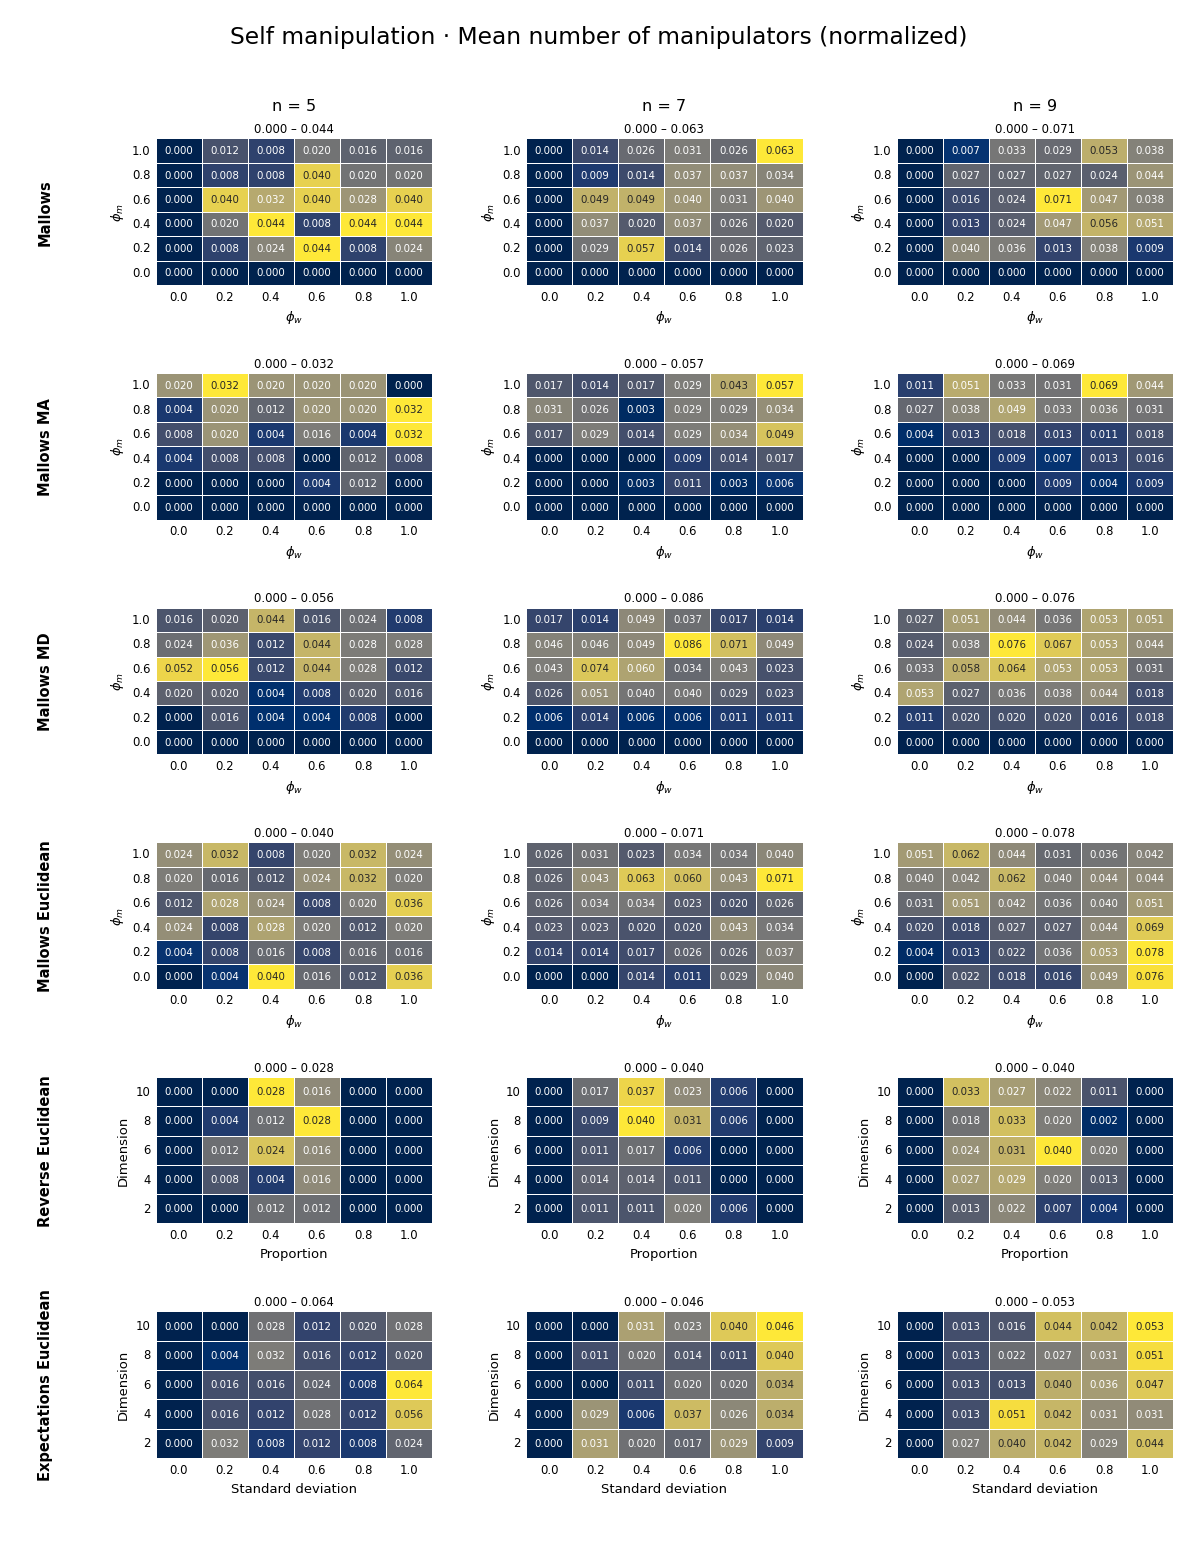

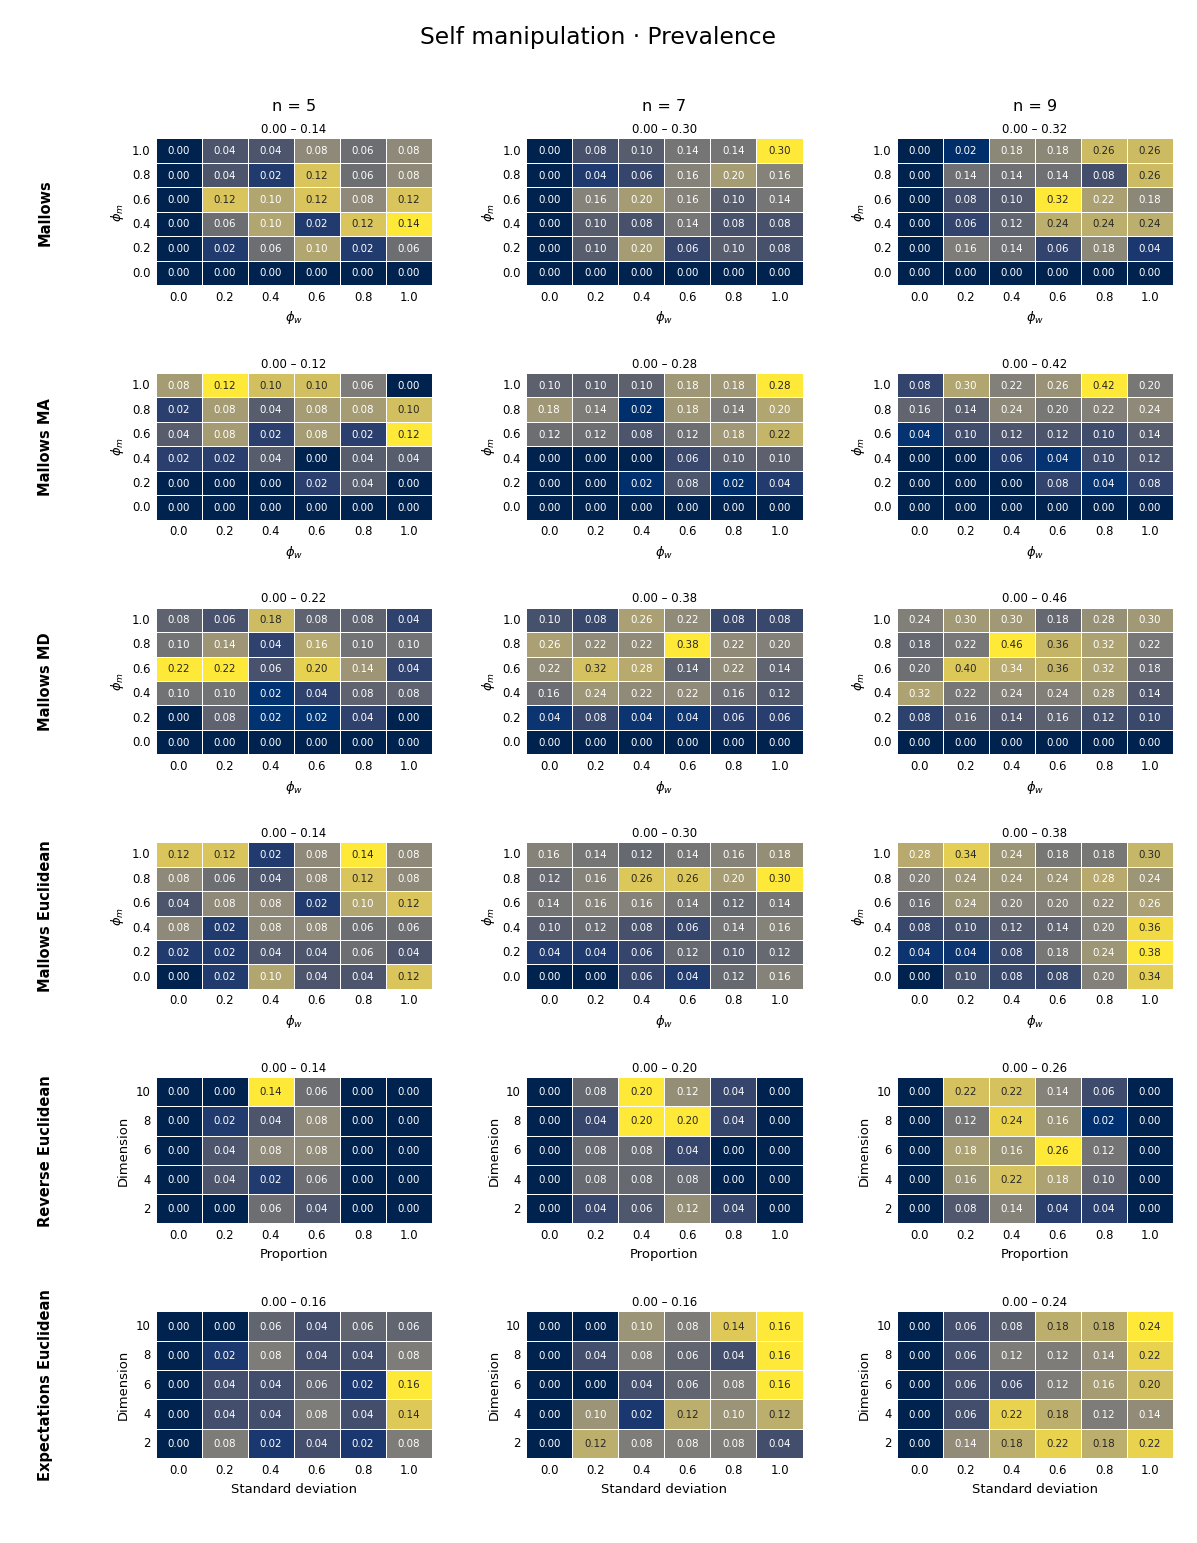

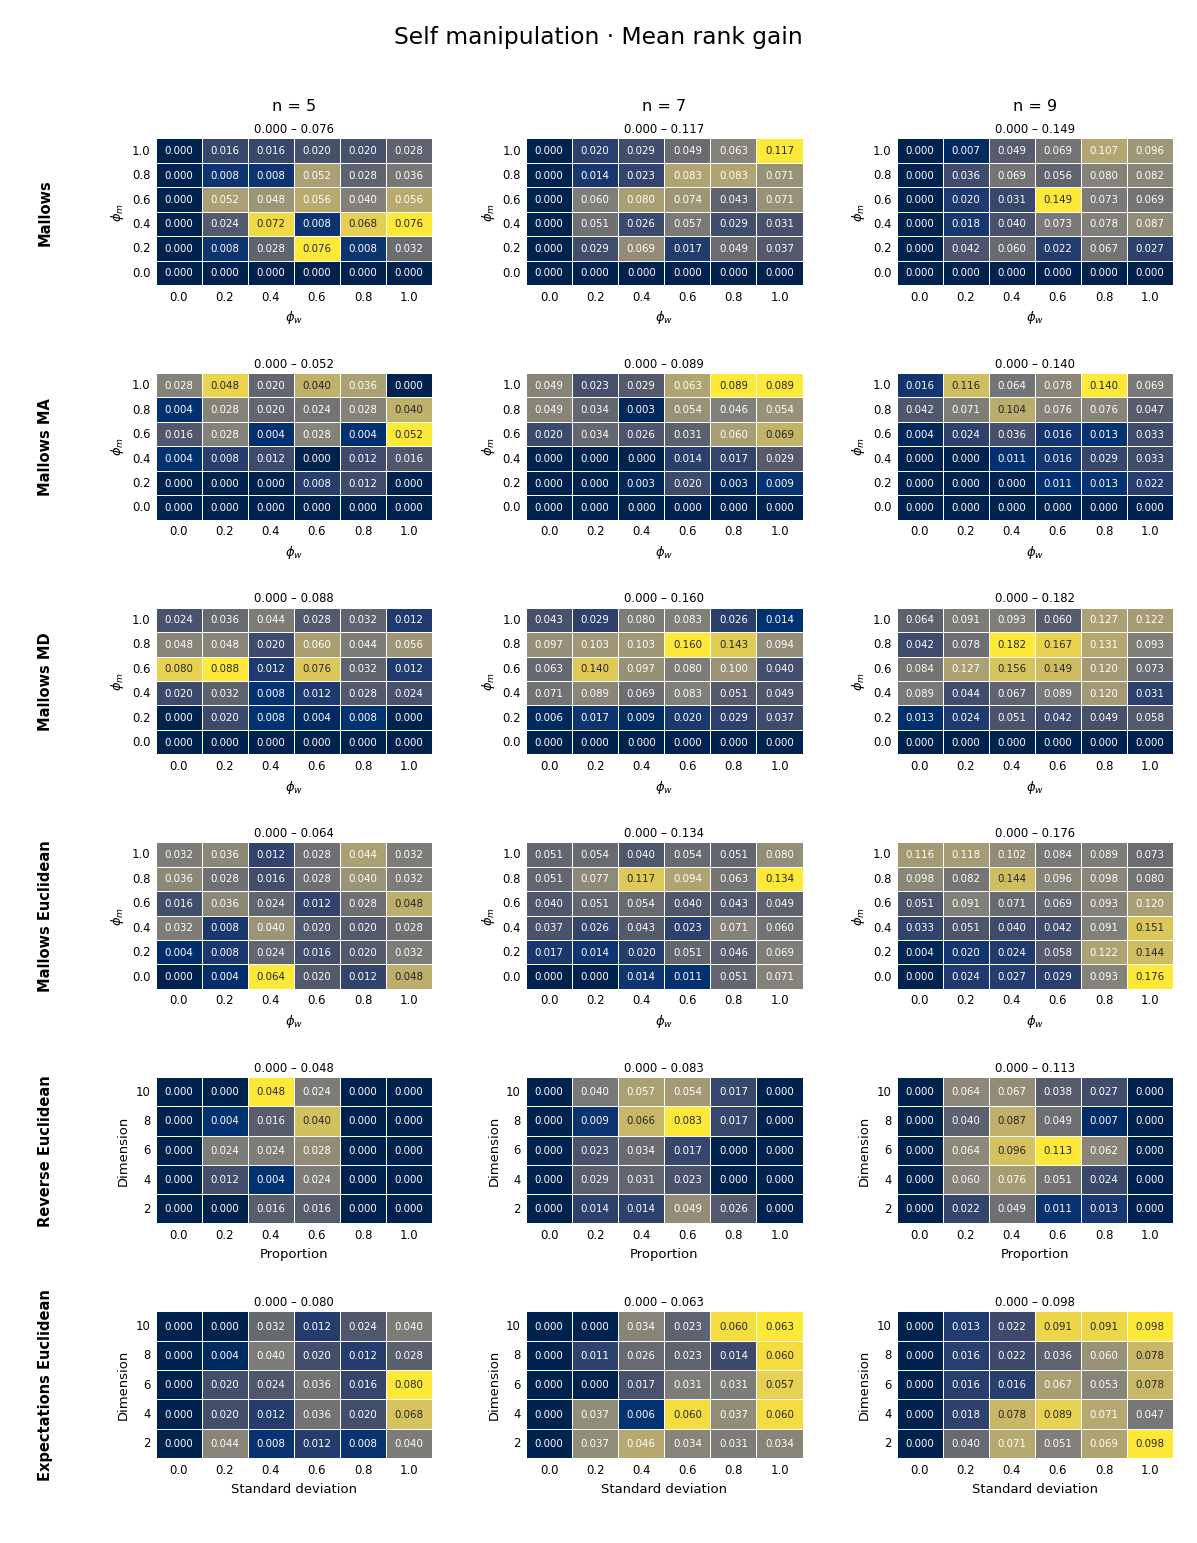

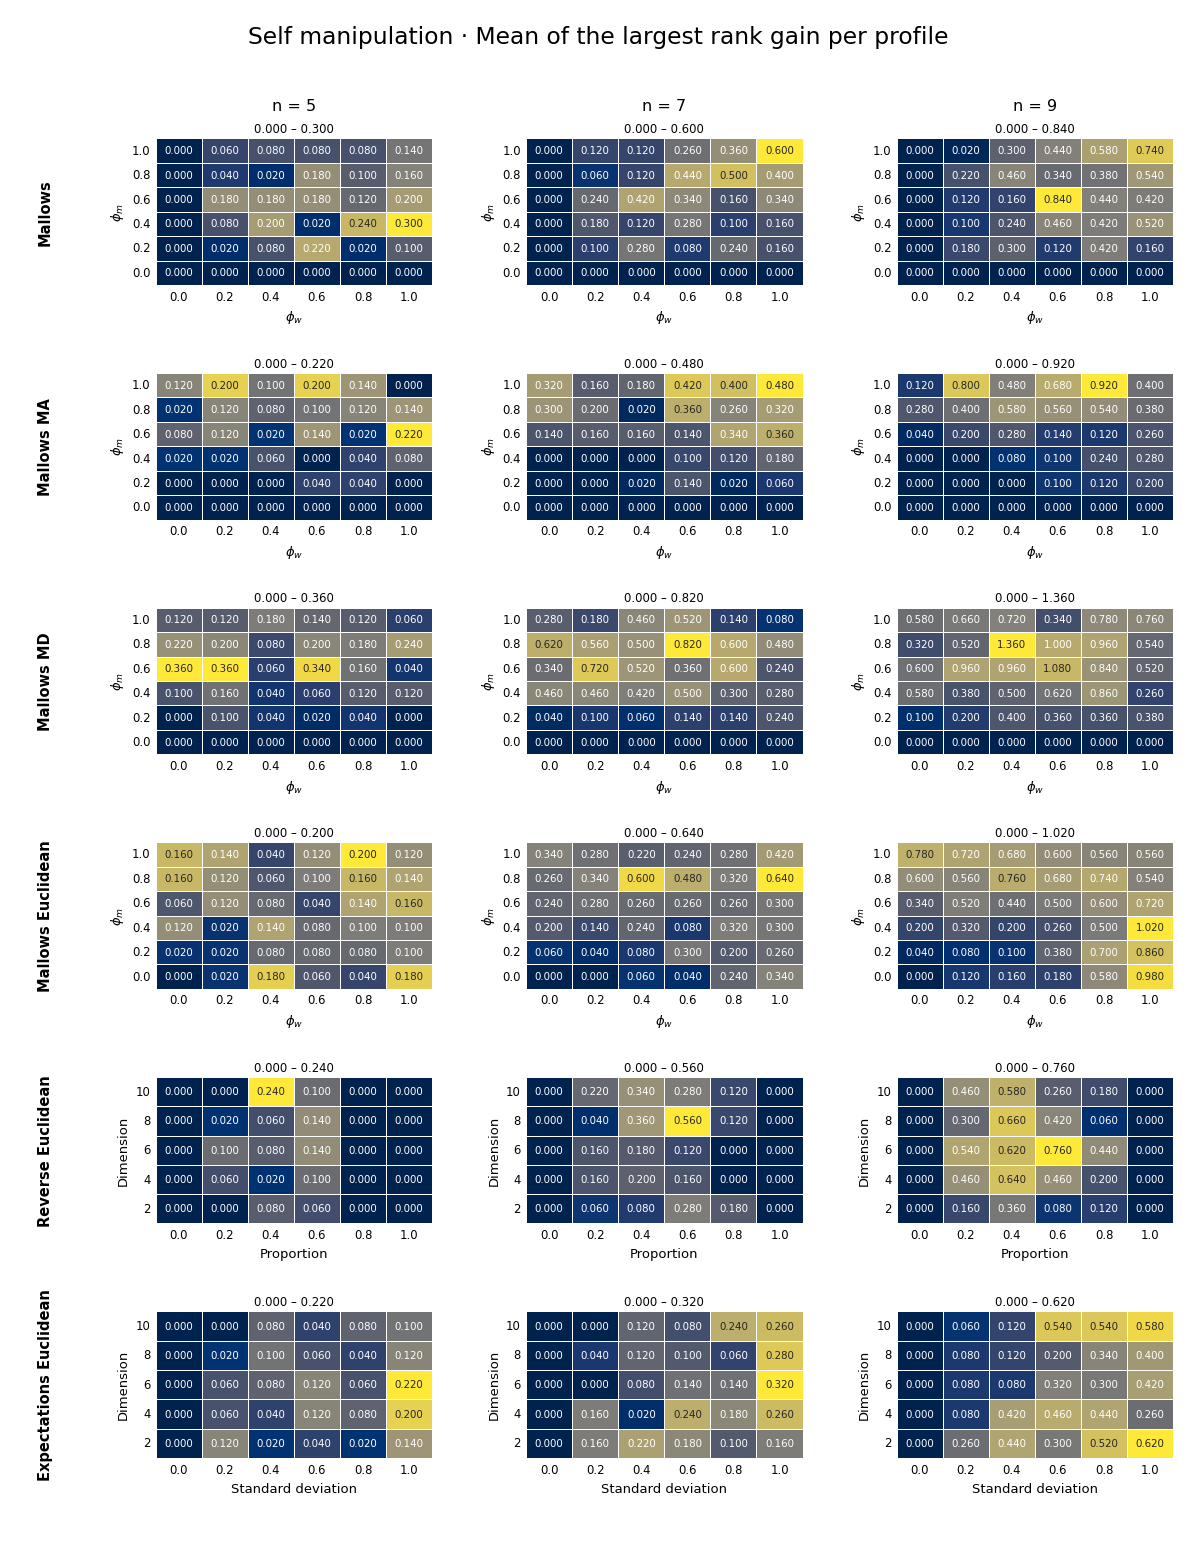

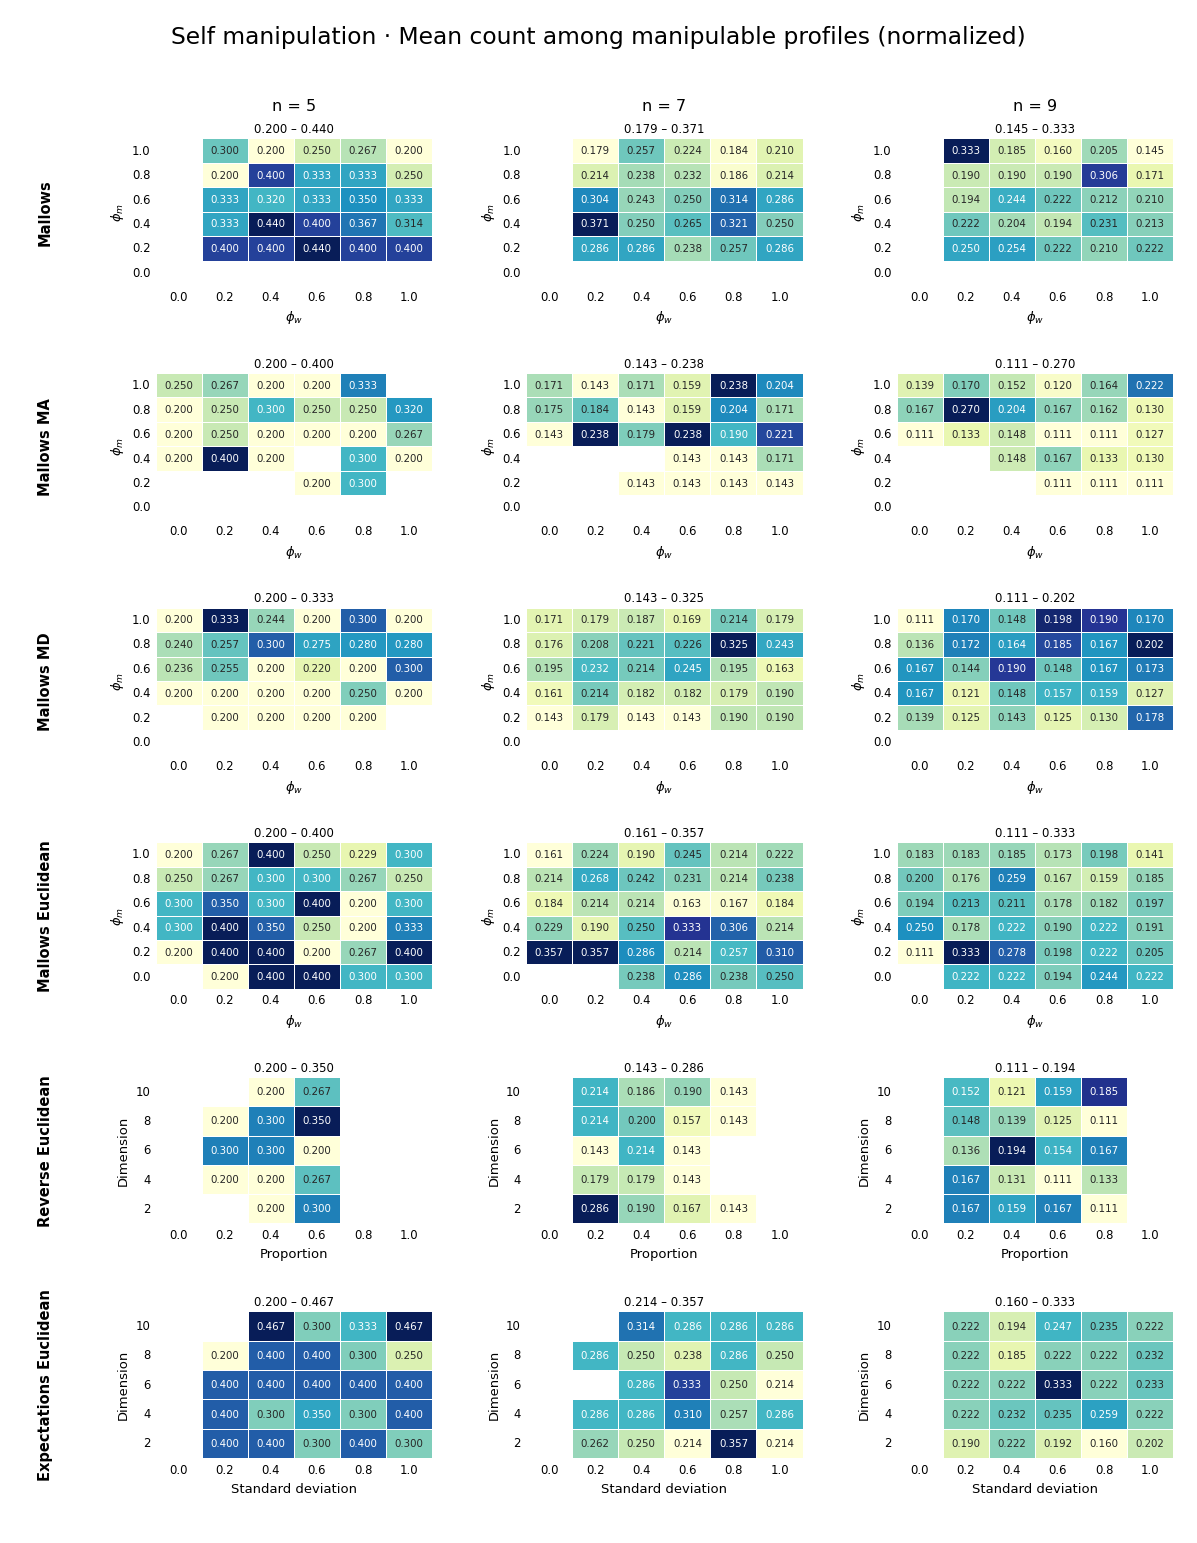

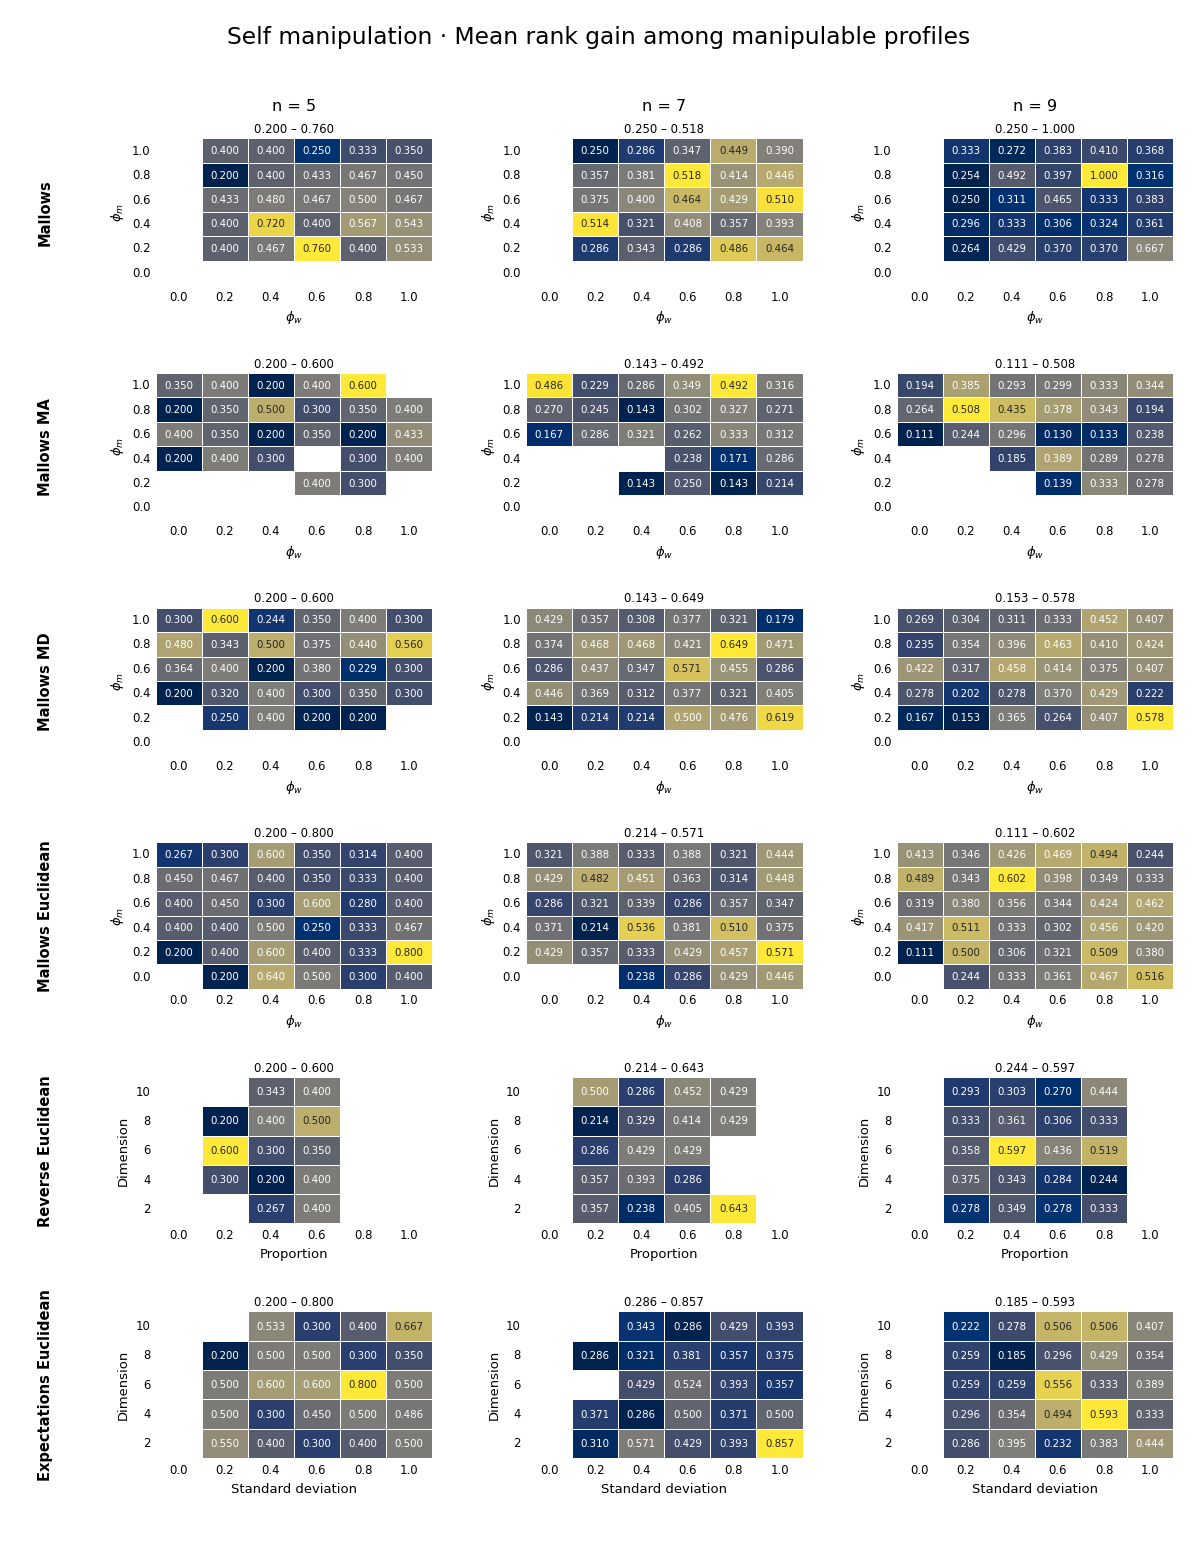

In [3]:
plot_heatmaps("self_manipulating_women", "Self manipulation · Mean number of manipulators", "cividis")
plot_heatmaps("self_freq_instance", "Self manipulation · Prevalence", "cividis", prevalence=True)
plot_heatmaps("avg_self_benefit", "Self manipulation · Mean rank gain", "cividis")
plot_heatmaps("max_self_benefit", "Self manipulation · Mean of the largest rank gain per profile", "cividis")
plot_heatmaps("self_count_conditional", "Self manipulation · Mean count among manipulable profiles", "YlGnBu")
plot_heatmaps("self_gain_conditional", "Self manipulation · Mean rank gain among manipulable profiles", "cividis")

## Accomplice manipulation

A woman's best gain is the largest rank gain available from any accomplice. Pair counts count each woman and accomplice combination with a positive gain.

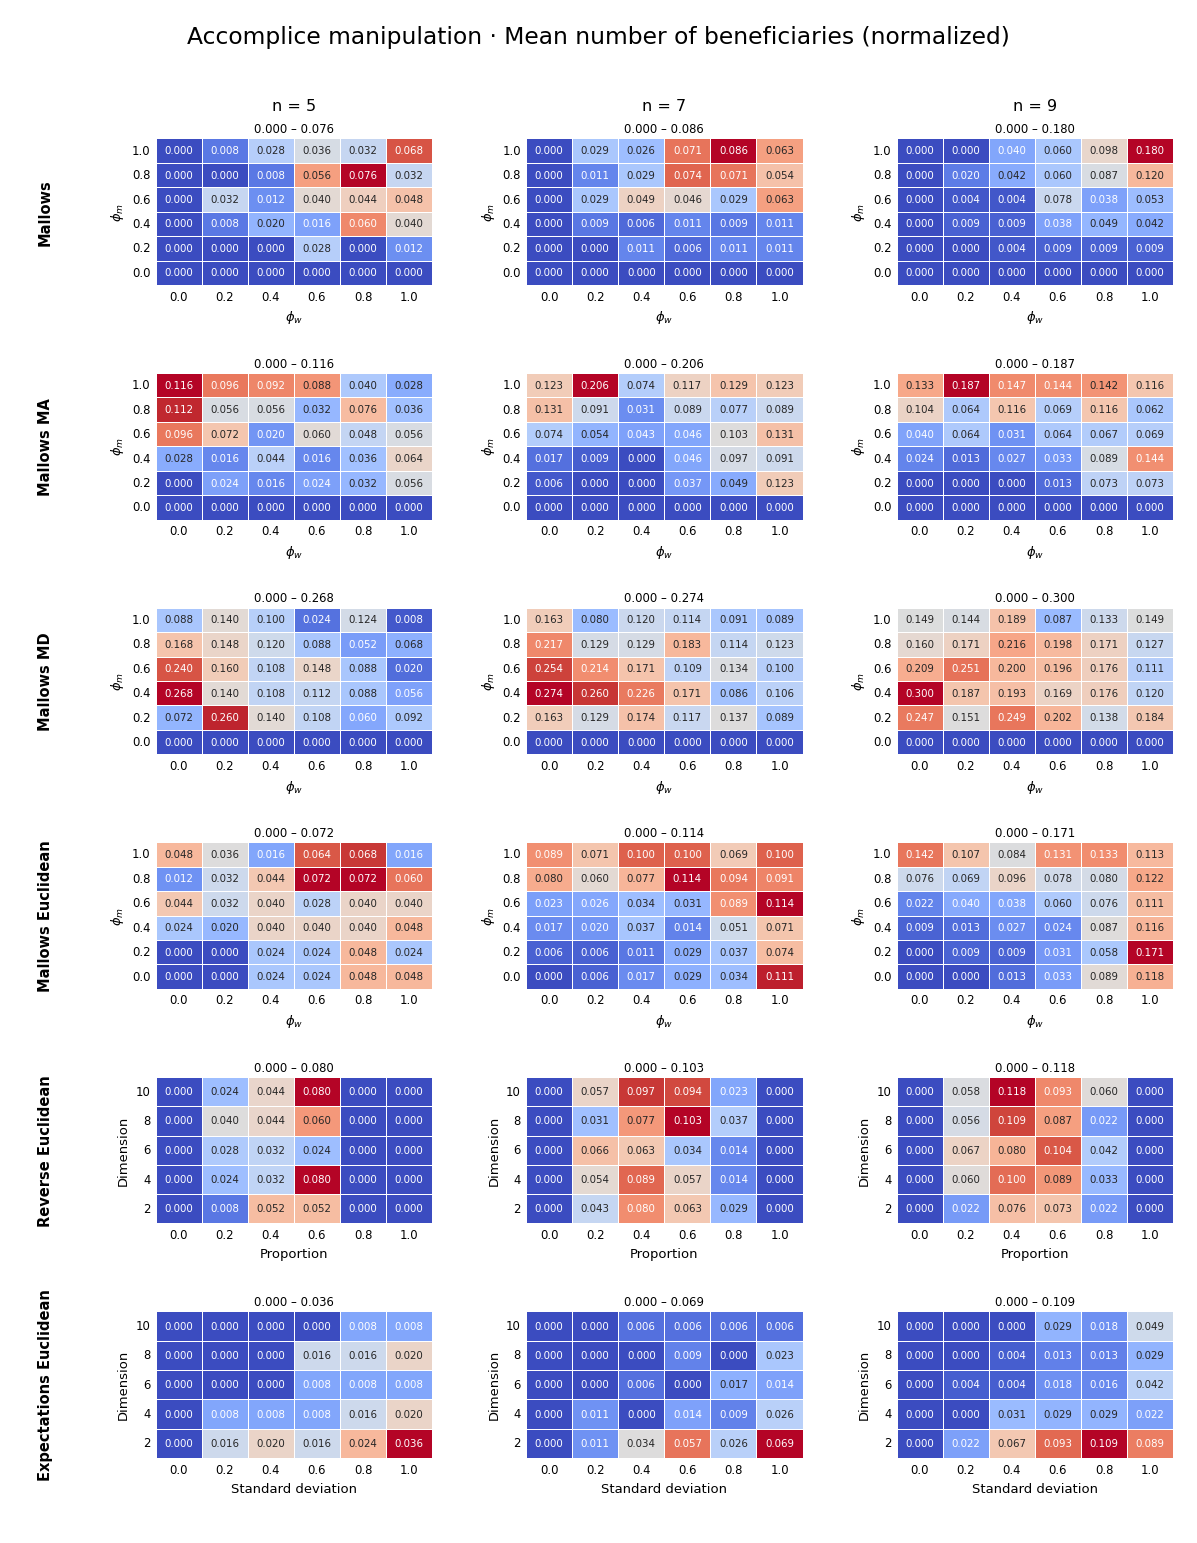

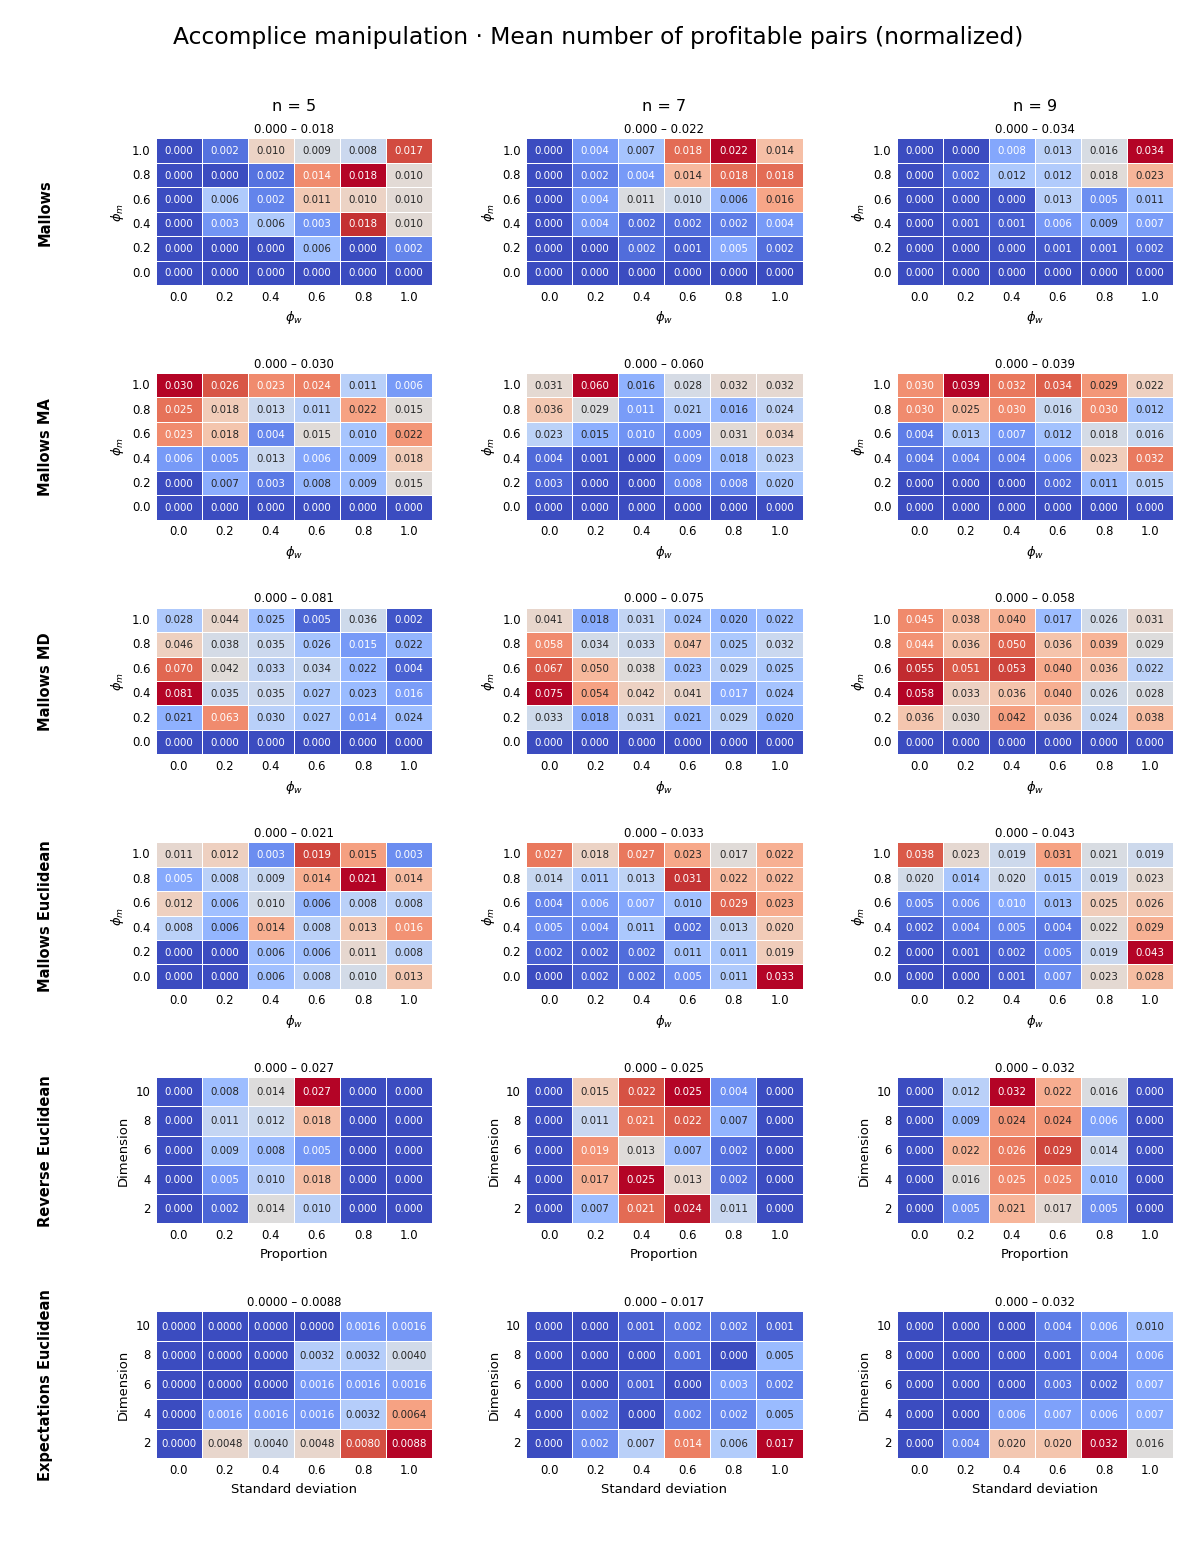

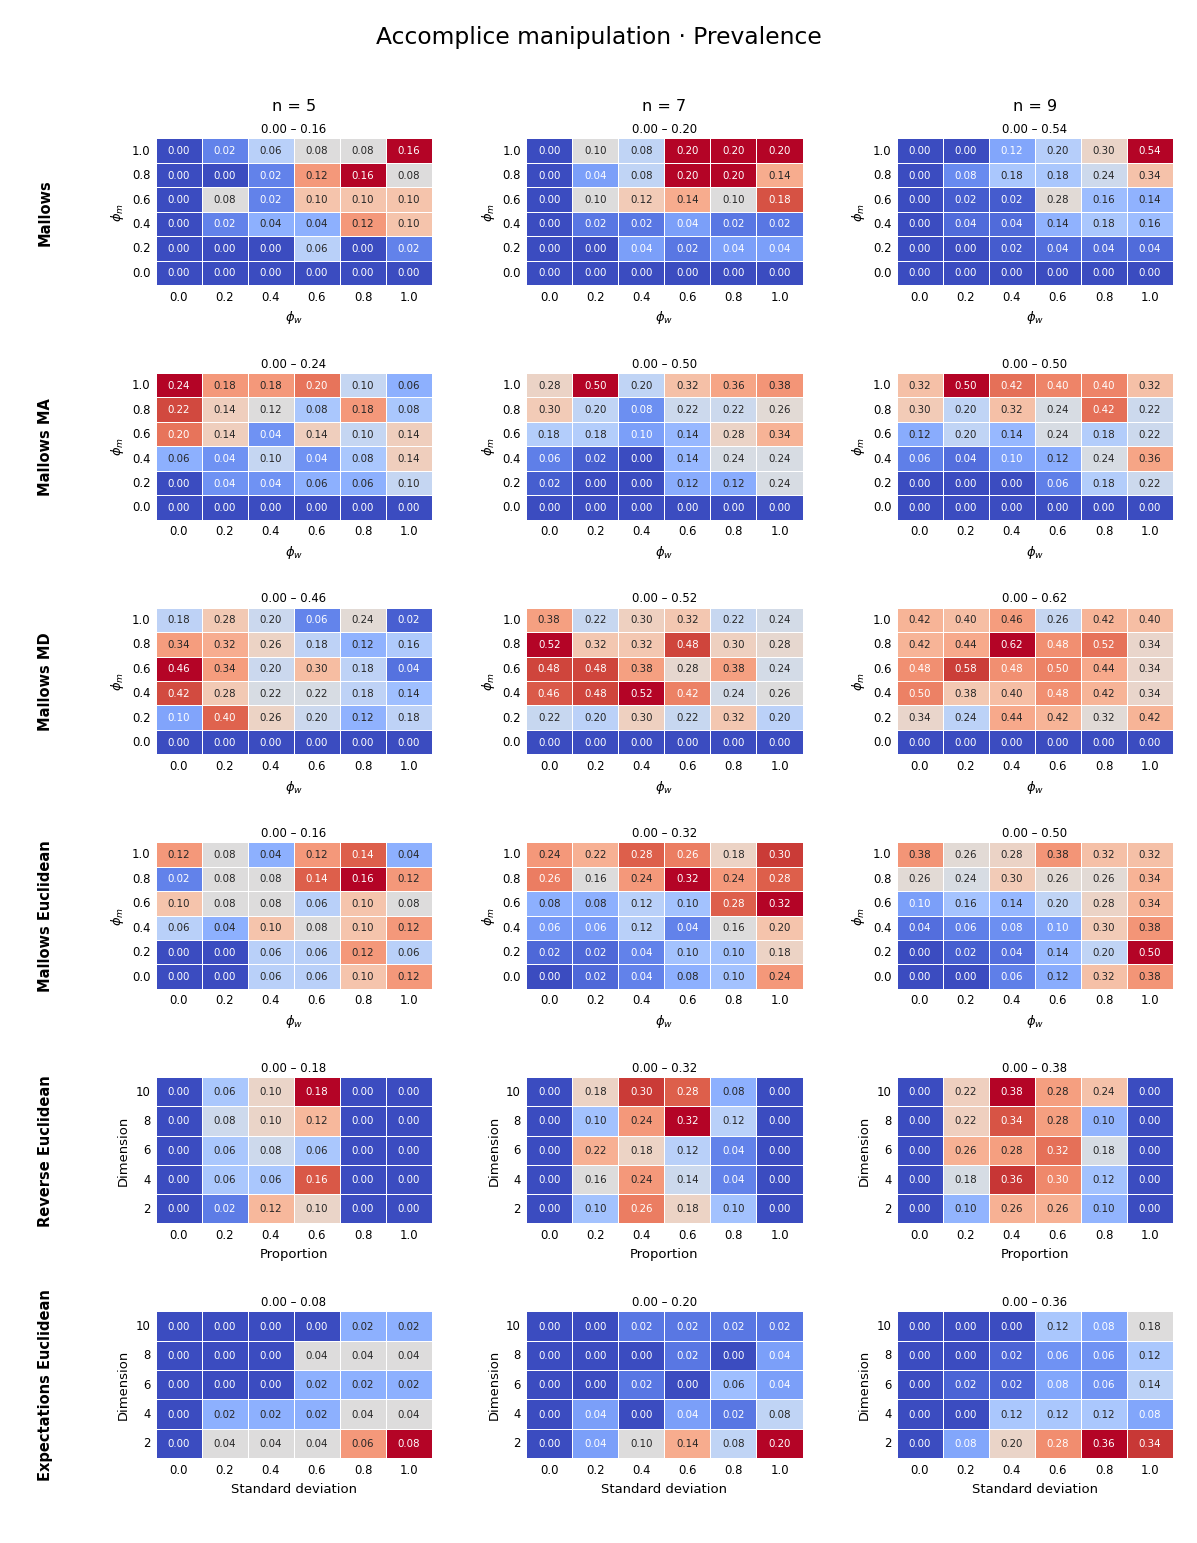

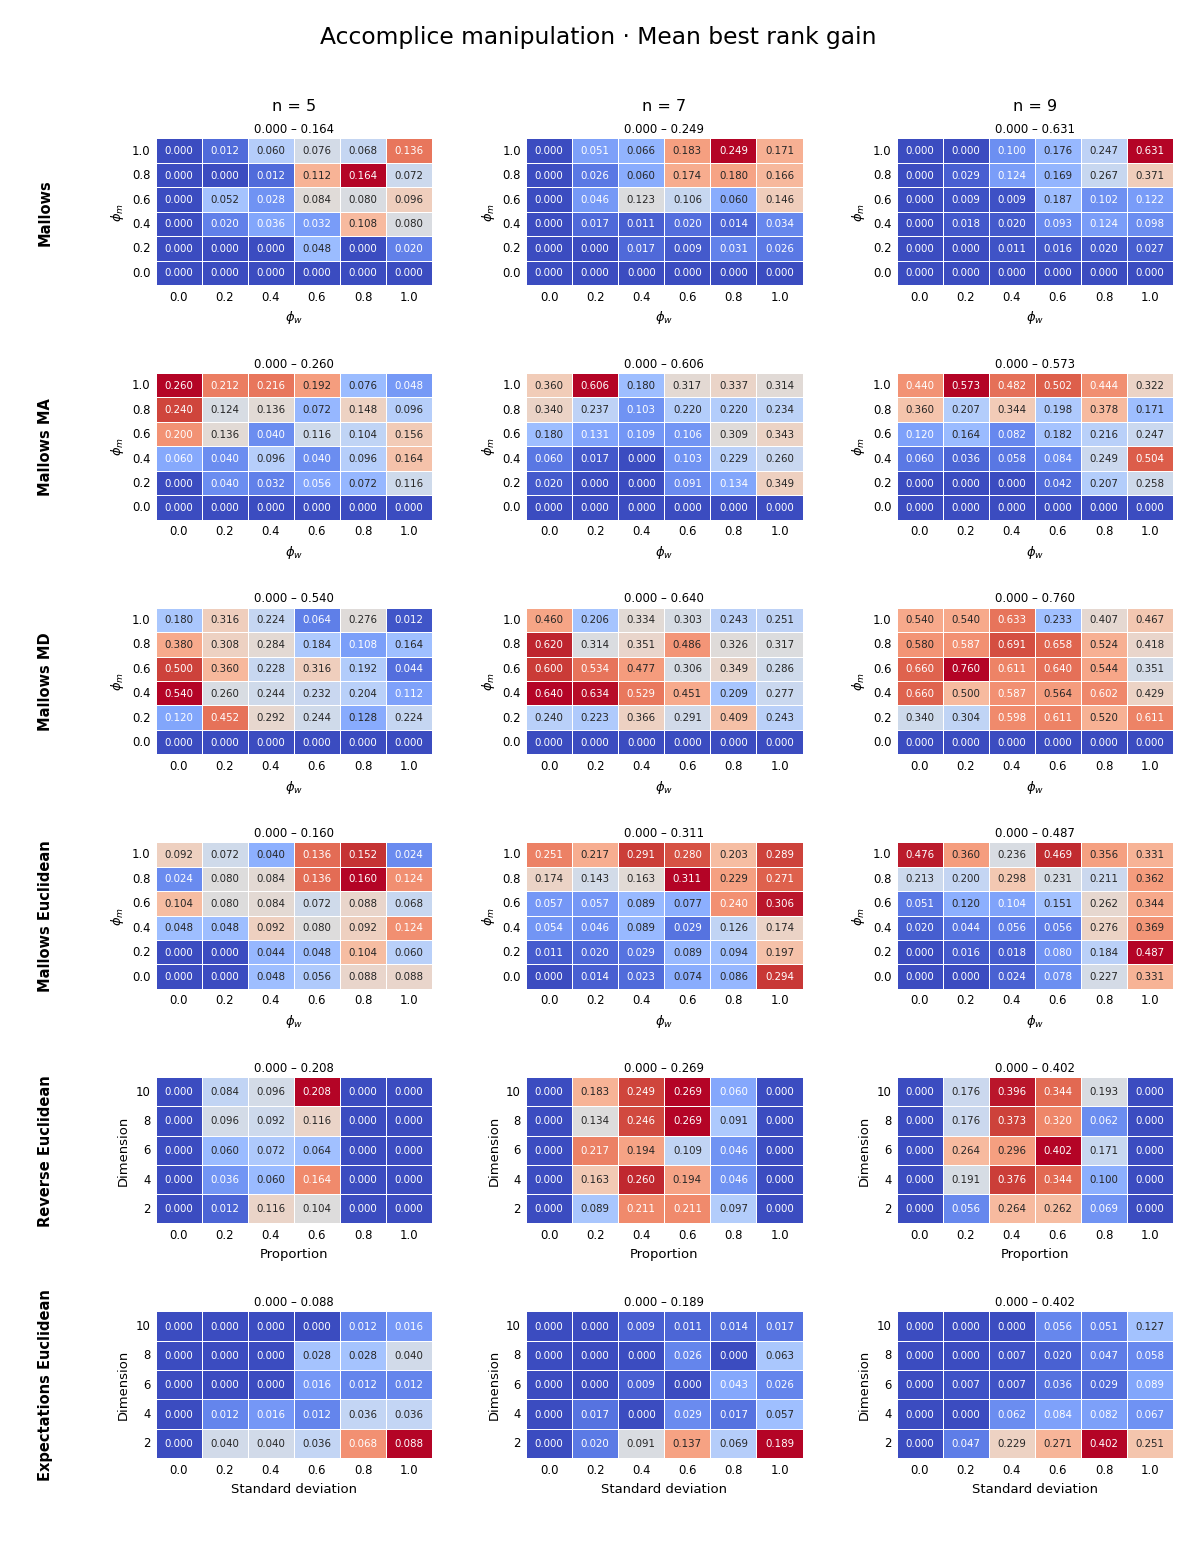

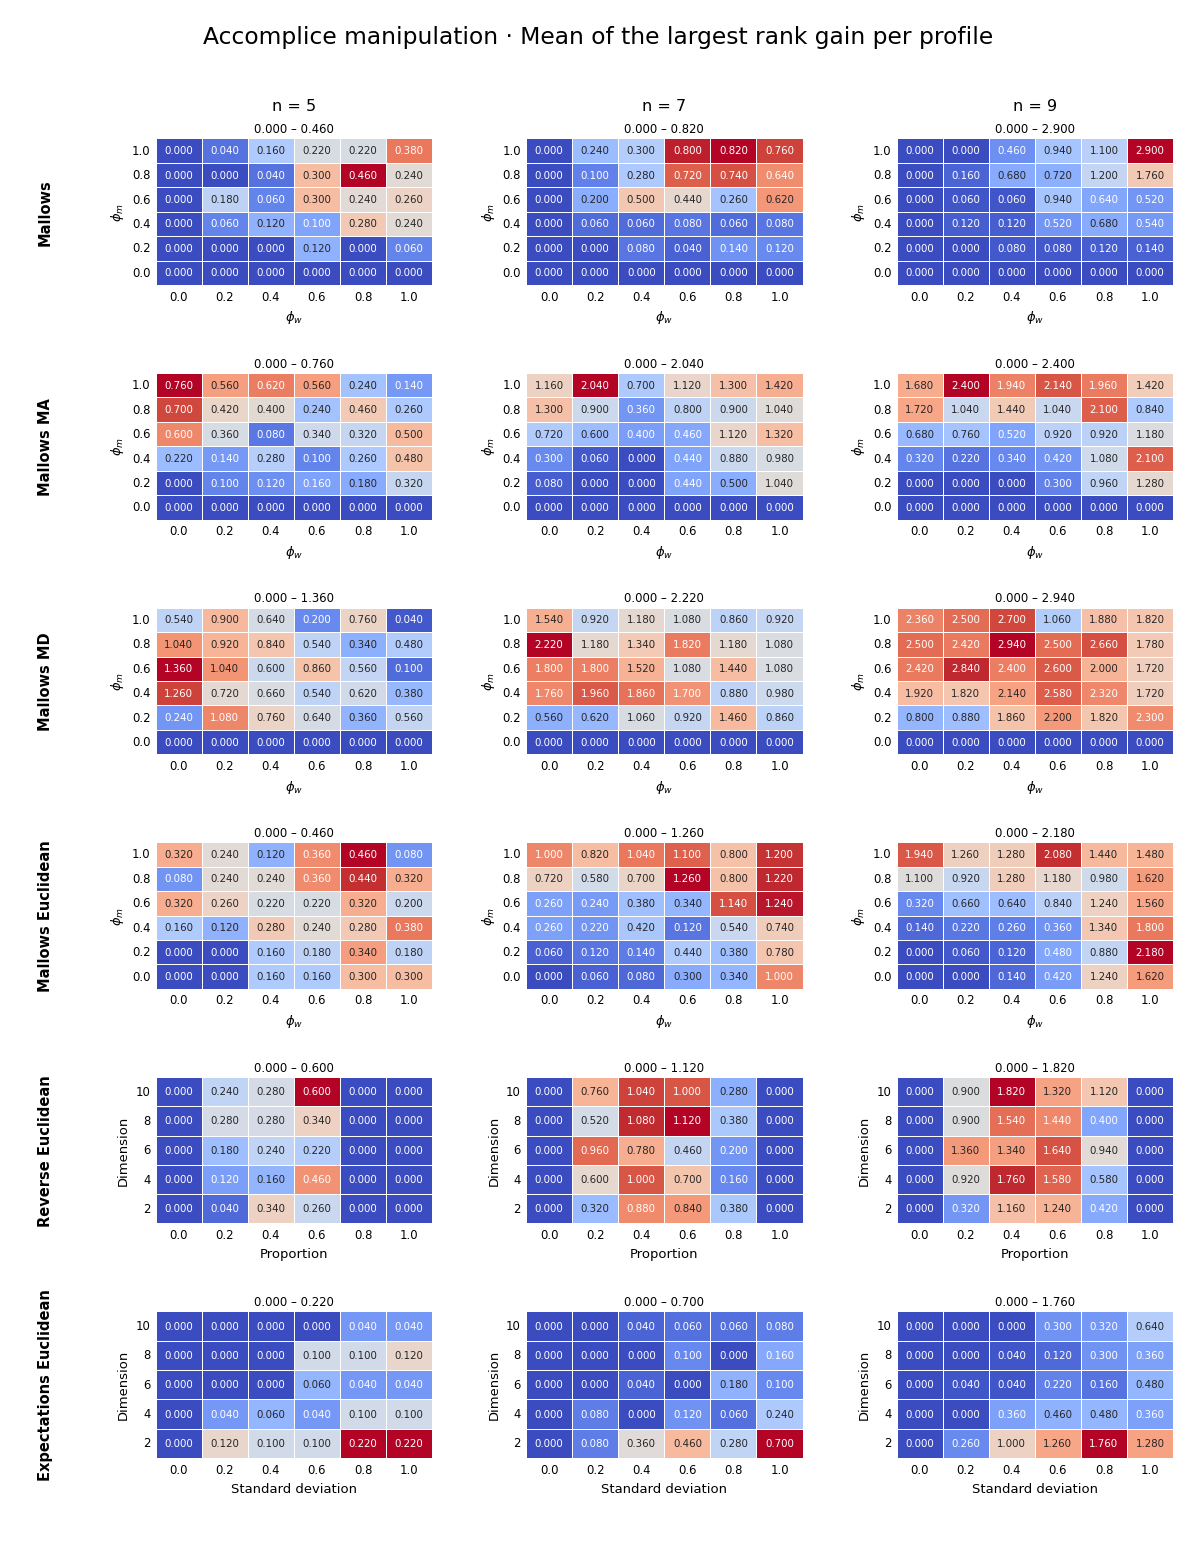

In [4]:
plot_heatmaps("count_woman", "Accomplice manipulation · Mean number of beneficiaries", "coolwarm")
plot_heatmaps("number_acc_pairs", "Accomplice manipulation · Mean number of profitable pairs", "coolwarm")
plot_heatmaps("acc_freq_instance", "Accomplice manipulation · Prevalence", "coolwarm", prevalence=True)
plot_heatmaps("avg_best_benefit_acc", "Accomplice manipulation · Mean best rank gain", "coolwarm")
plot_heatmaps("max_best_benefit_acc", "Accomplice manipulation · Mean of the largest rank gain per profile", "coolwarm")

## Two-for-one manipulation

These plots use the original absolute rank-change measure. Prevalence and counts are based on positive recorded changes.

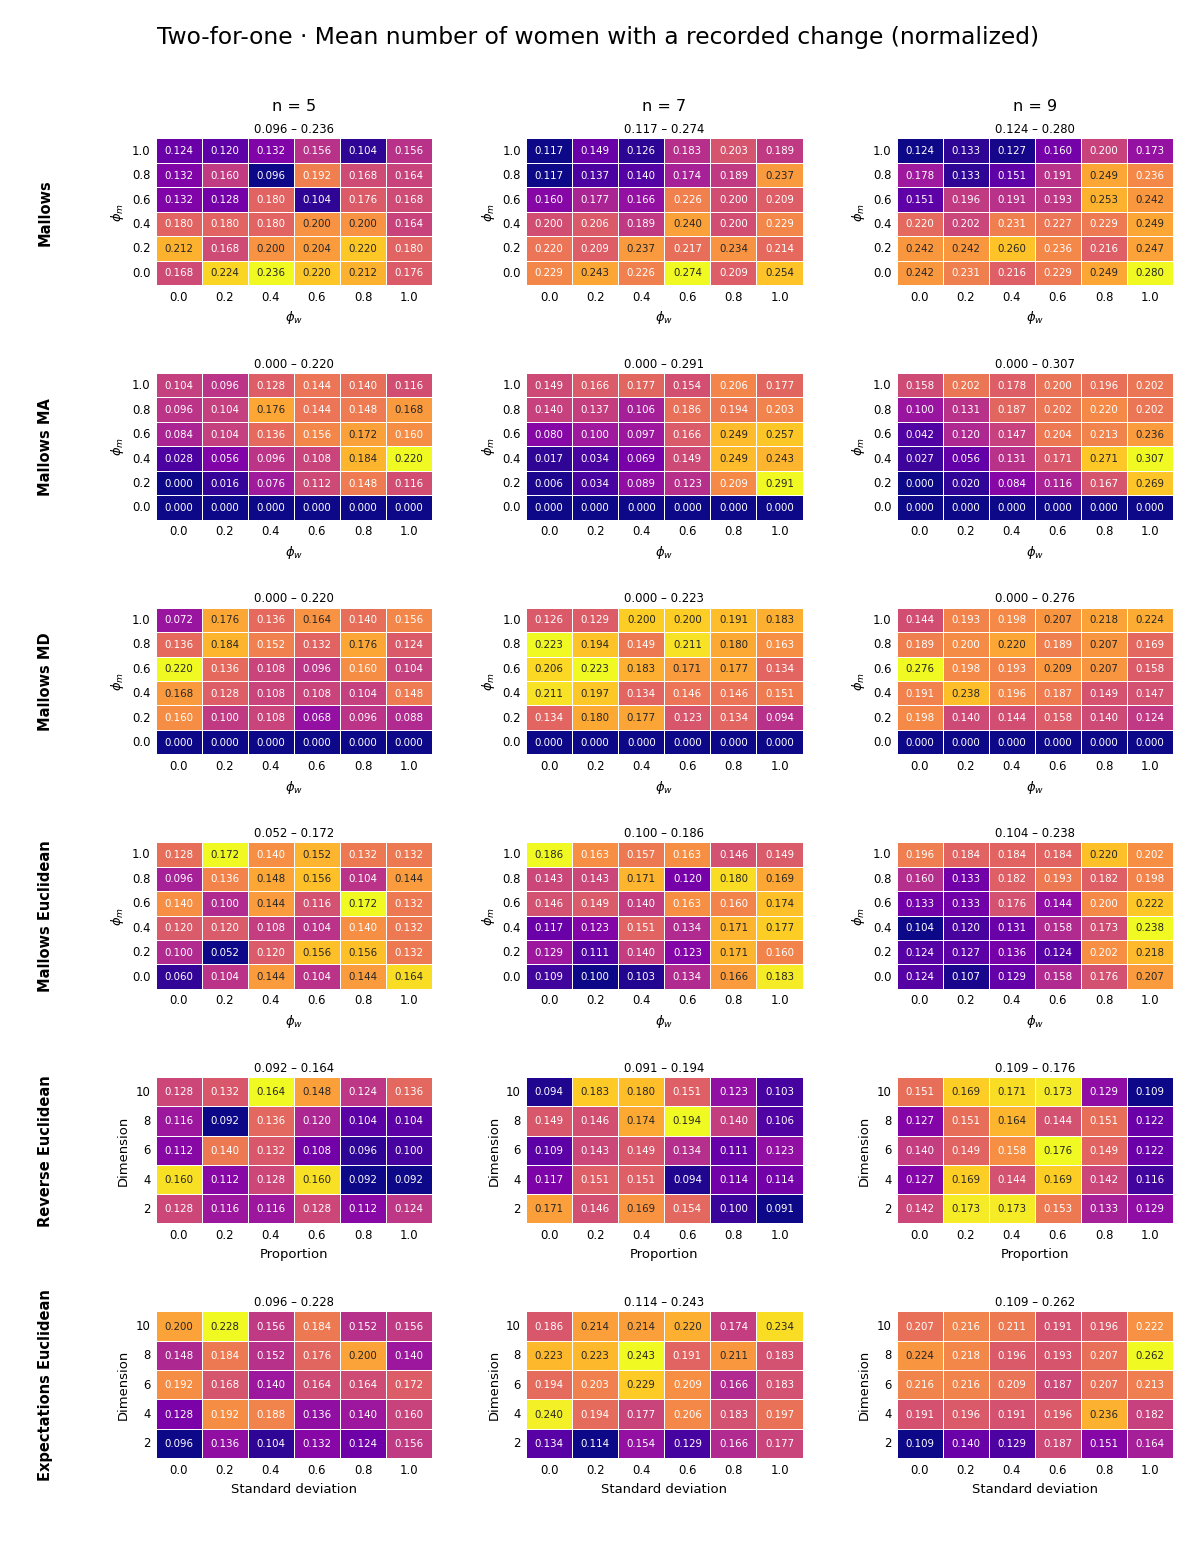

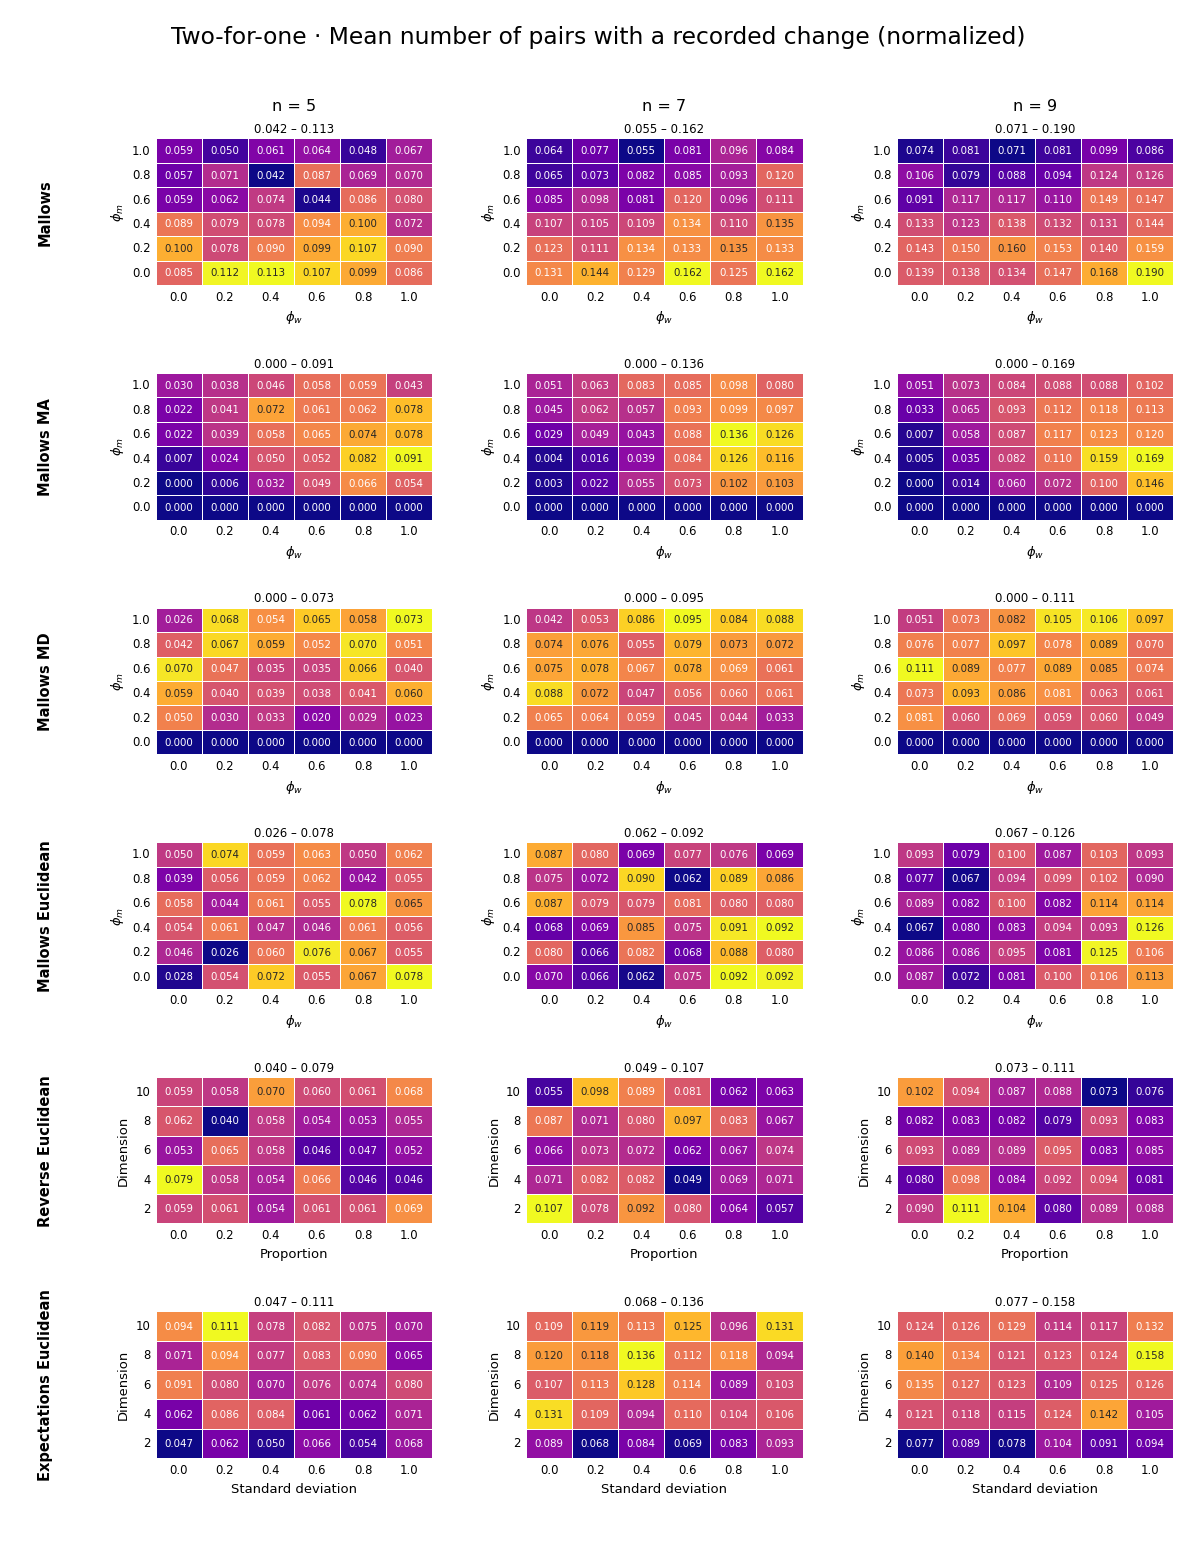

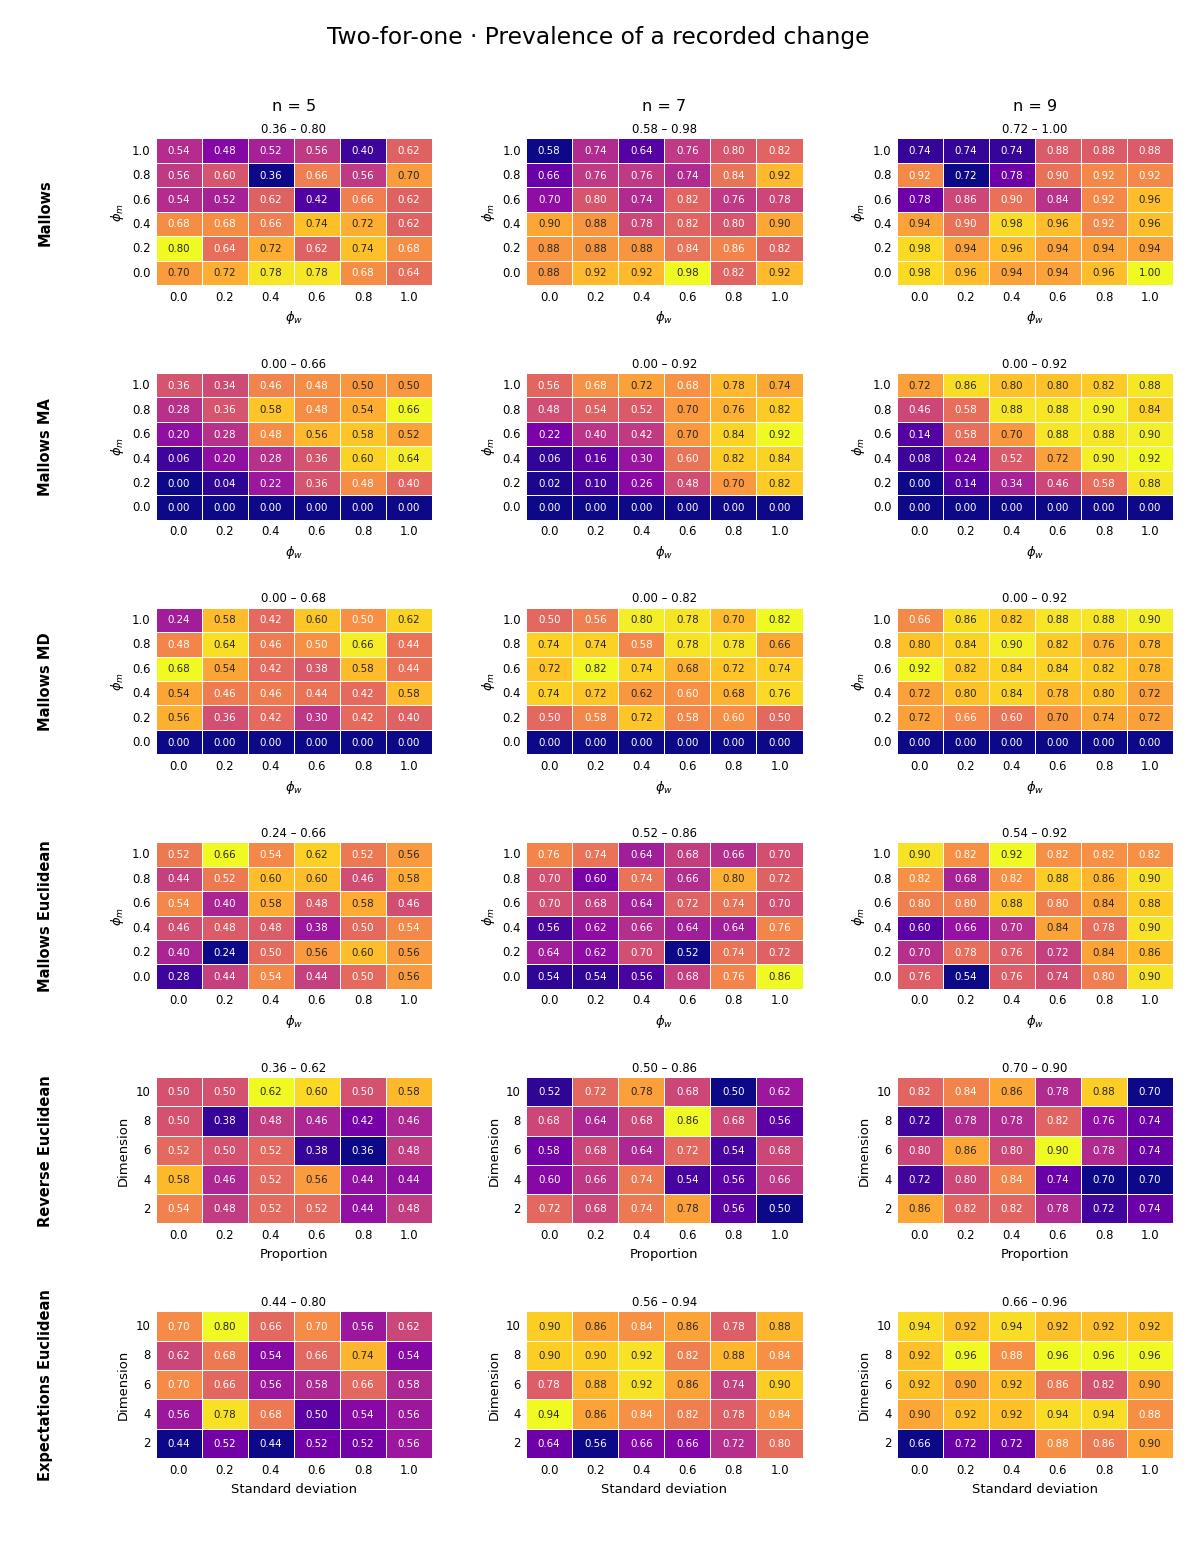

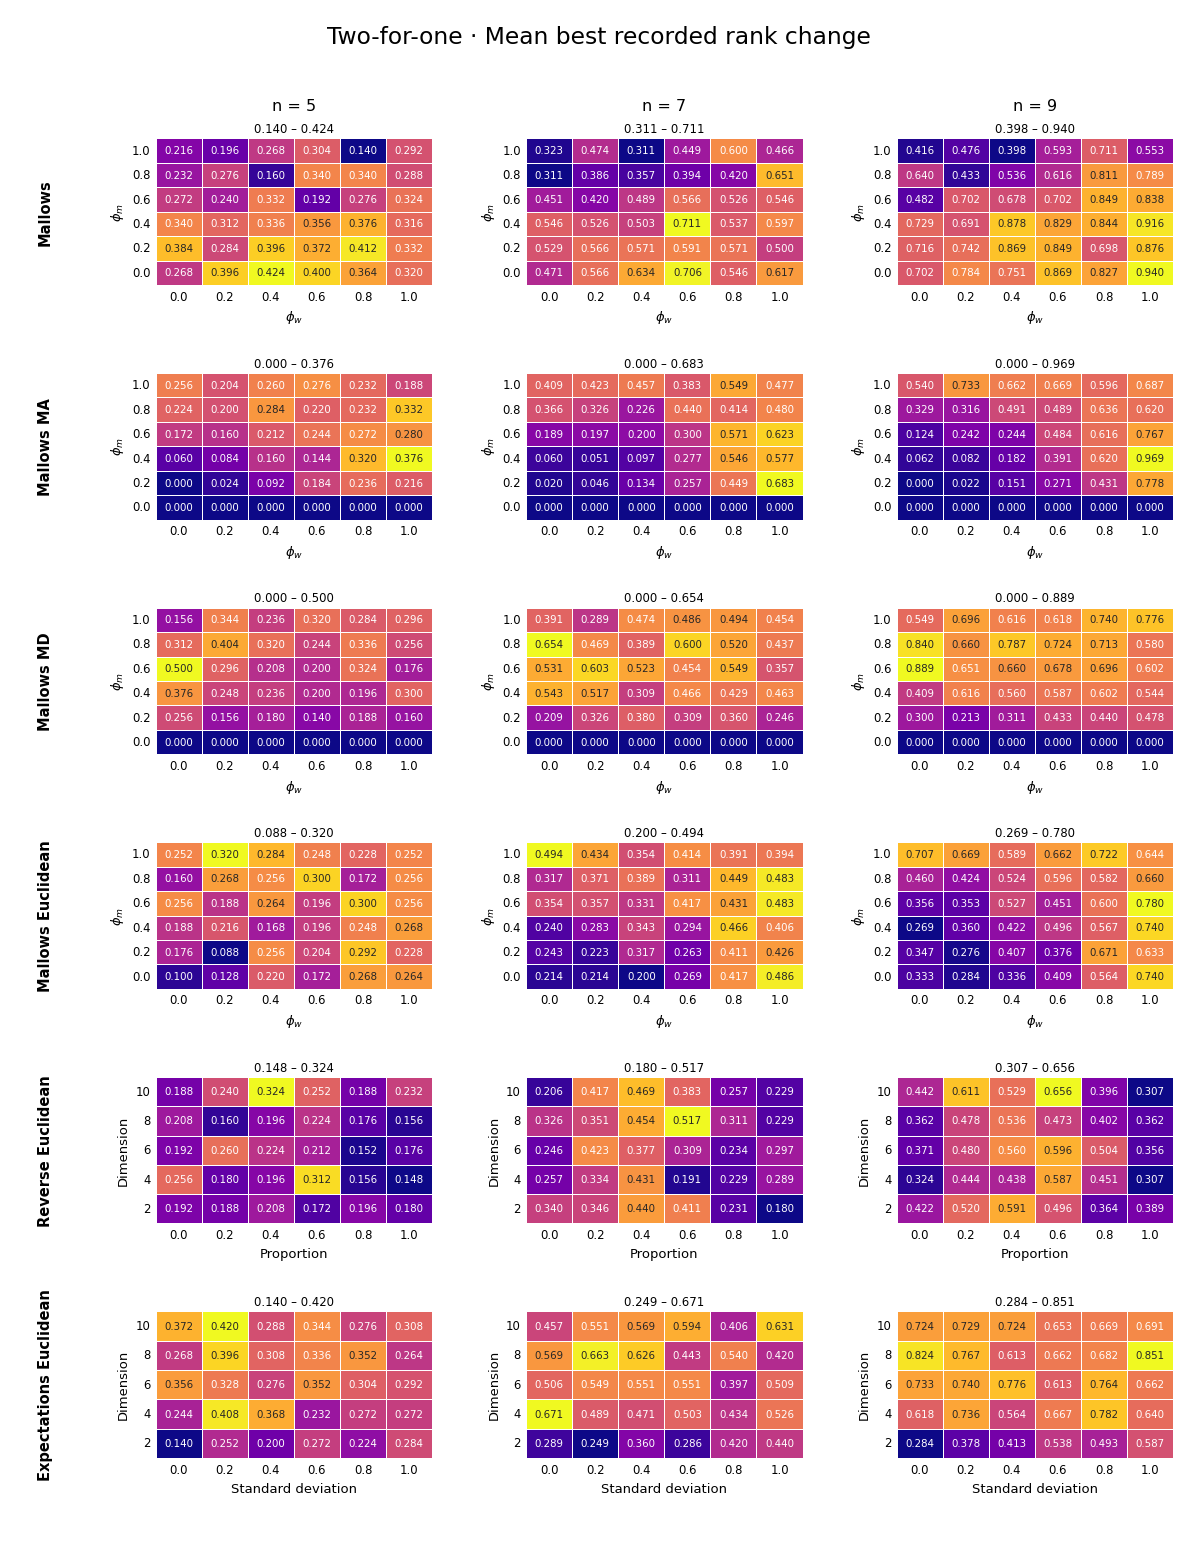

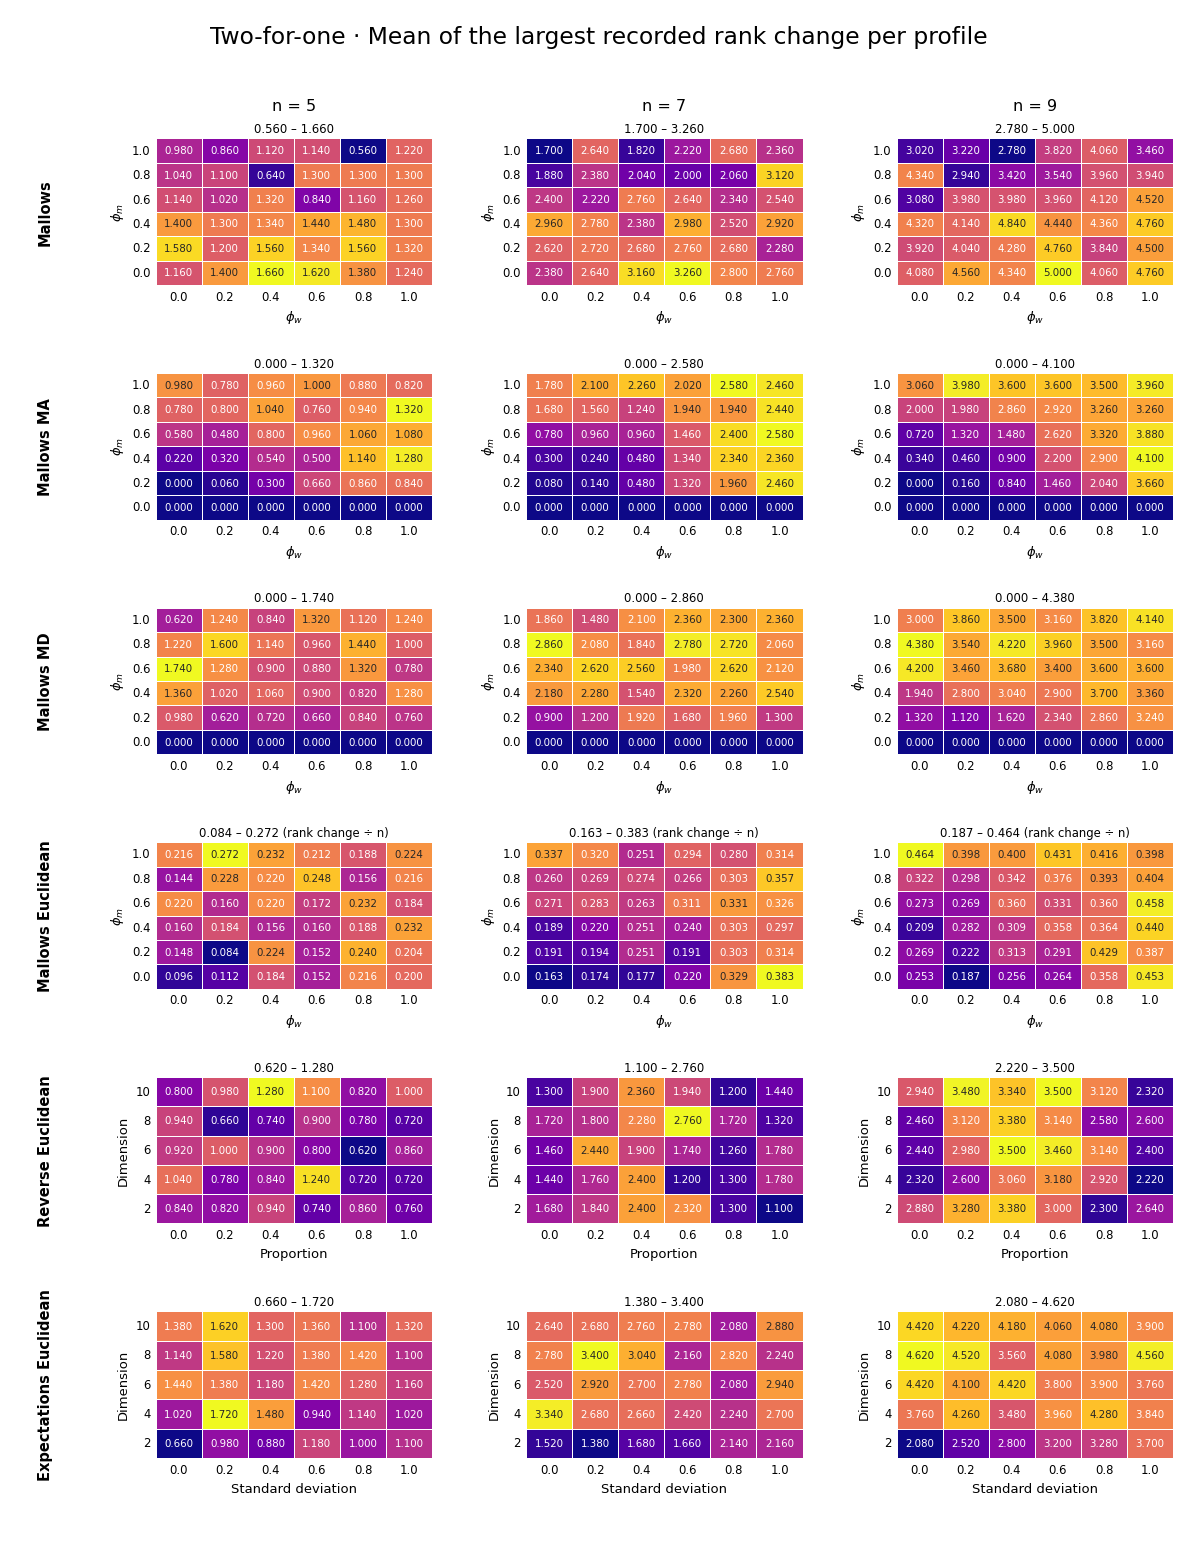

In [5]:
plot_heatmaps("number_two_manipulators", "Two-for-one · Mean number of women with a recorded change", "plasma")
plot_heatmaps("number_two_pairs", "Two-for-one · Mean number of pairs with a recorded change", "plasma")
plot_heatmaps("two_freq_instance", "Two-for-one · Prevalence of a recorded change", "plasma", prevalence=True)
plot_heatmaps("avg_best_benefit_two", "Two-for-one · Mean best recorded rank change", "plasma")
plot_heatmaps("max_best_benefit_two", "Two-for-one · Mean of the largest recorded rank change per profile", "plasma")

## Truncation

The count is the number of women whose woman-optimal partner improves on their man-optimal partner. Prevalence is the fraction of profiles with more than one stable matching.

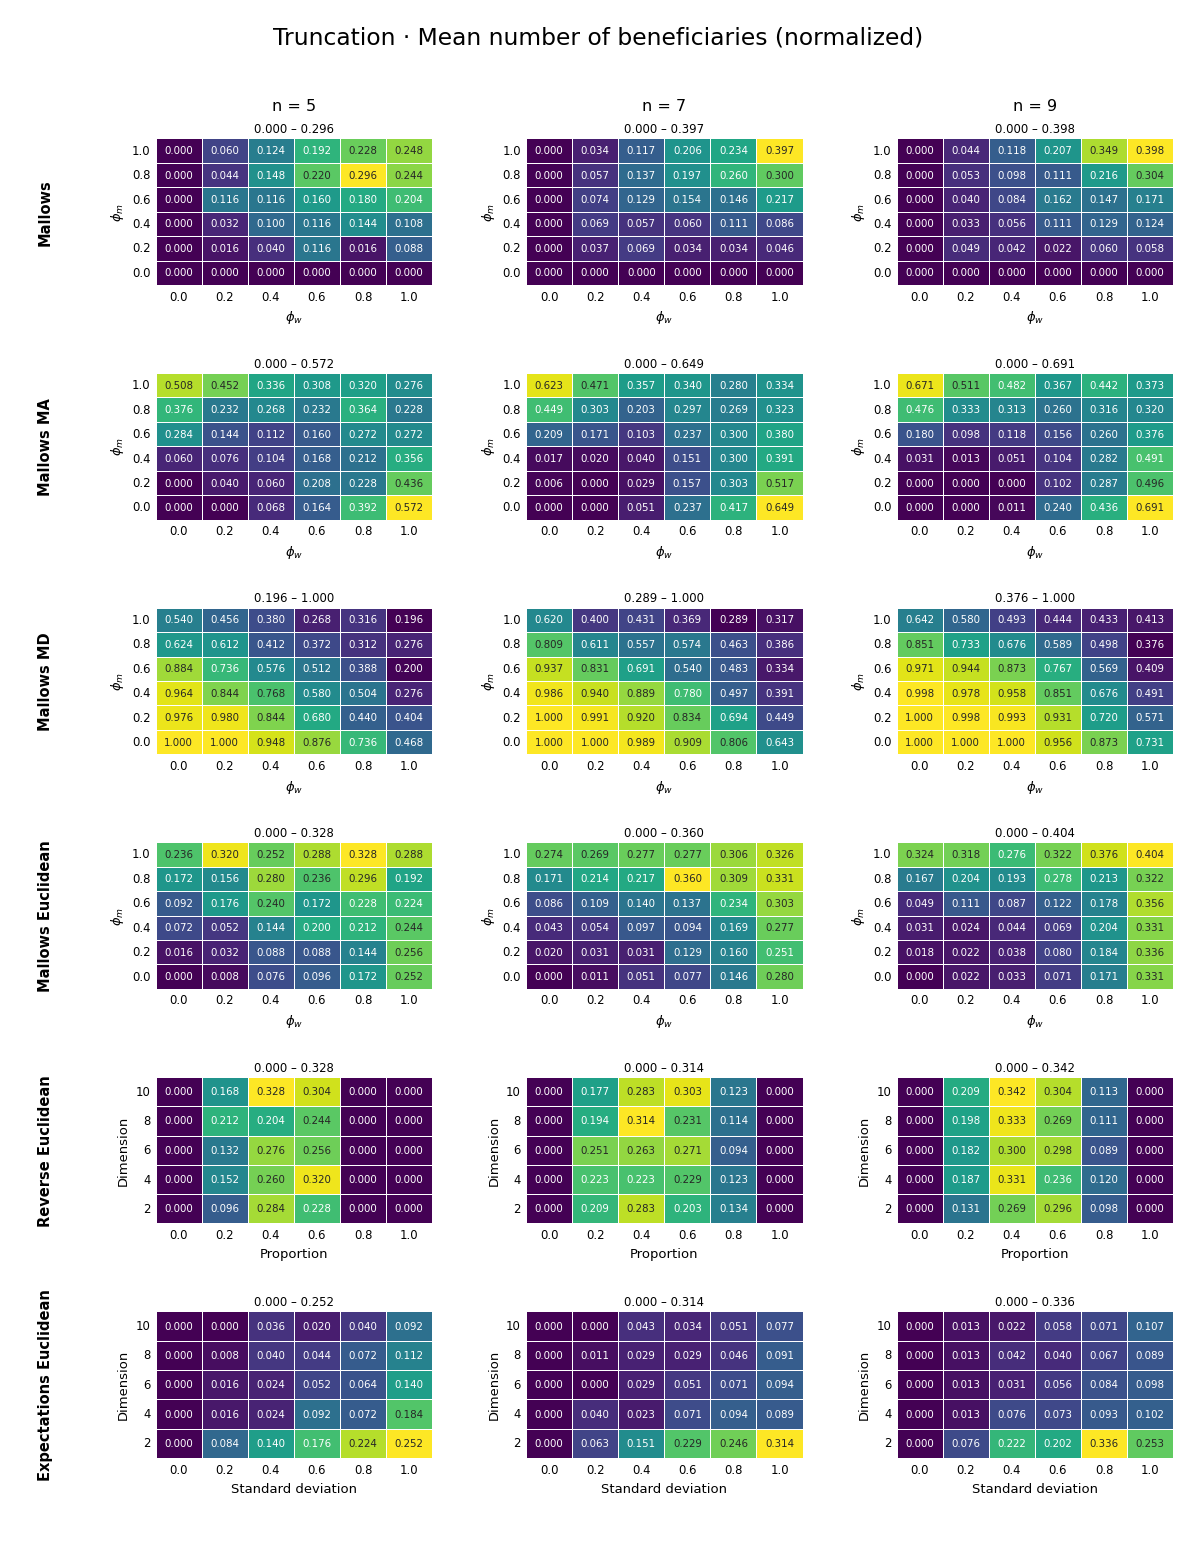

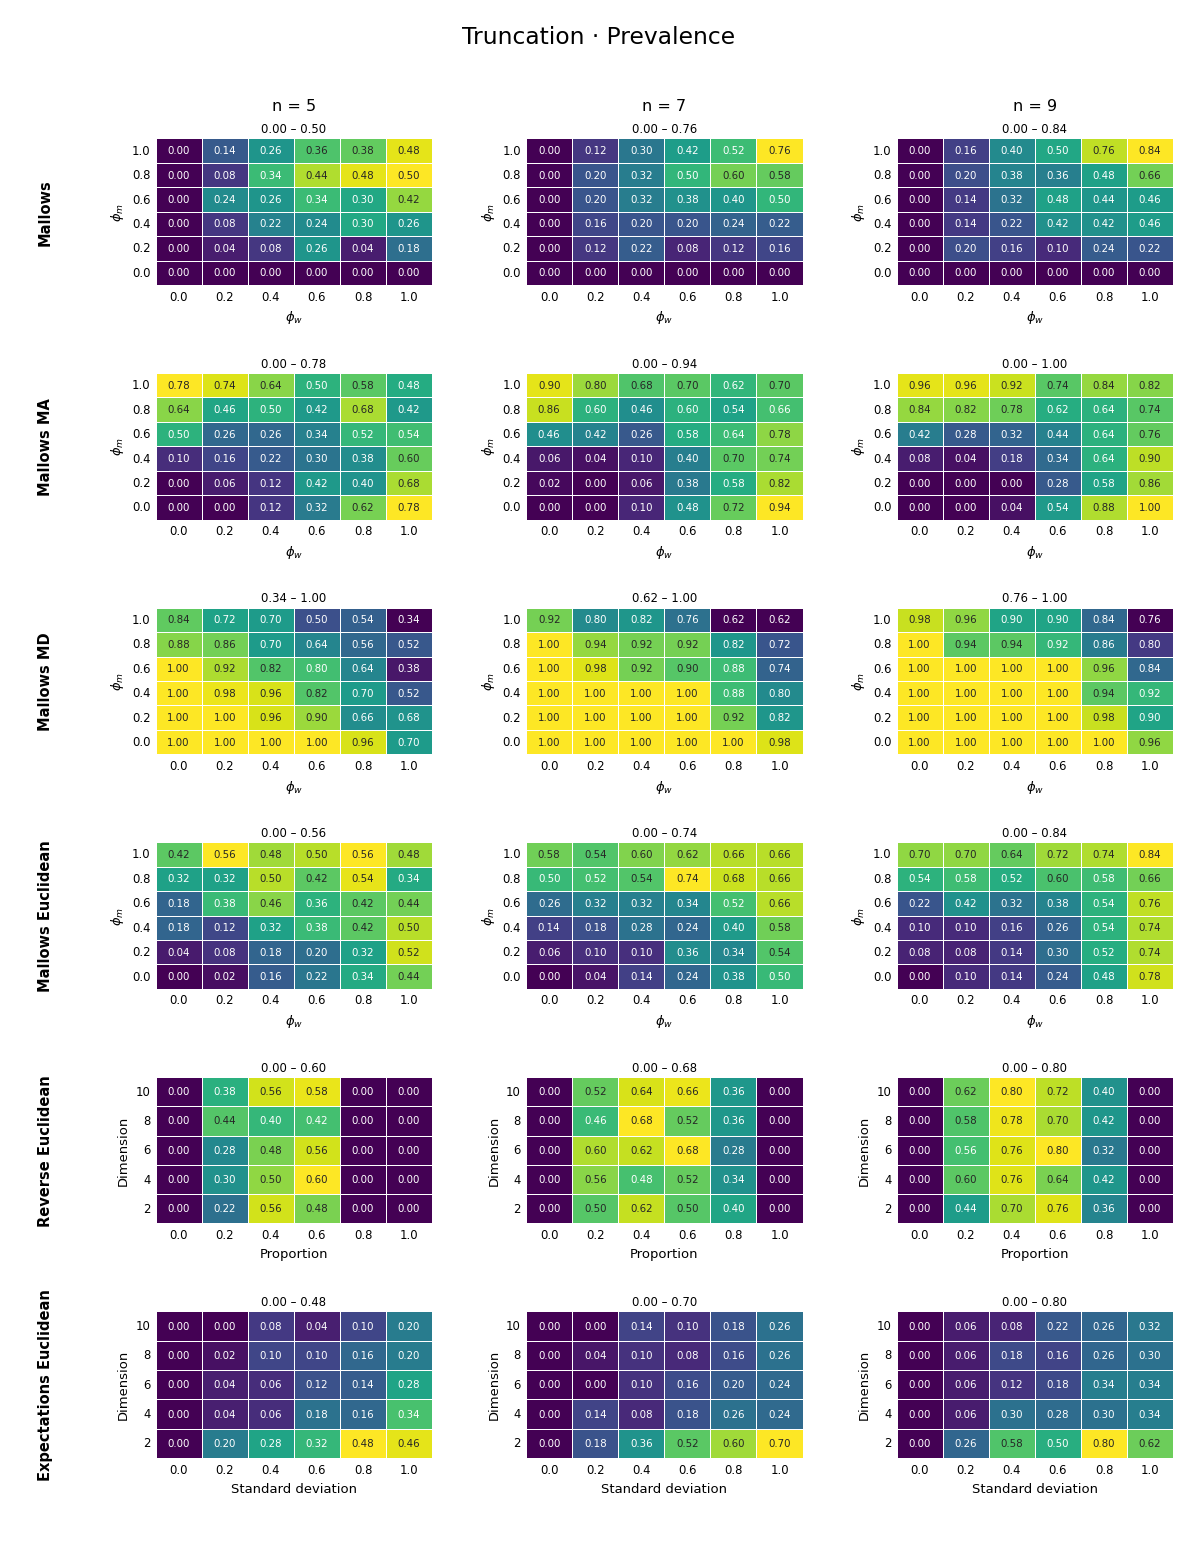

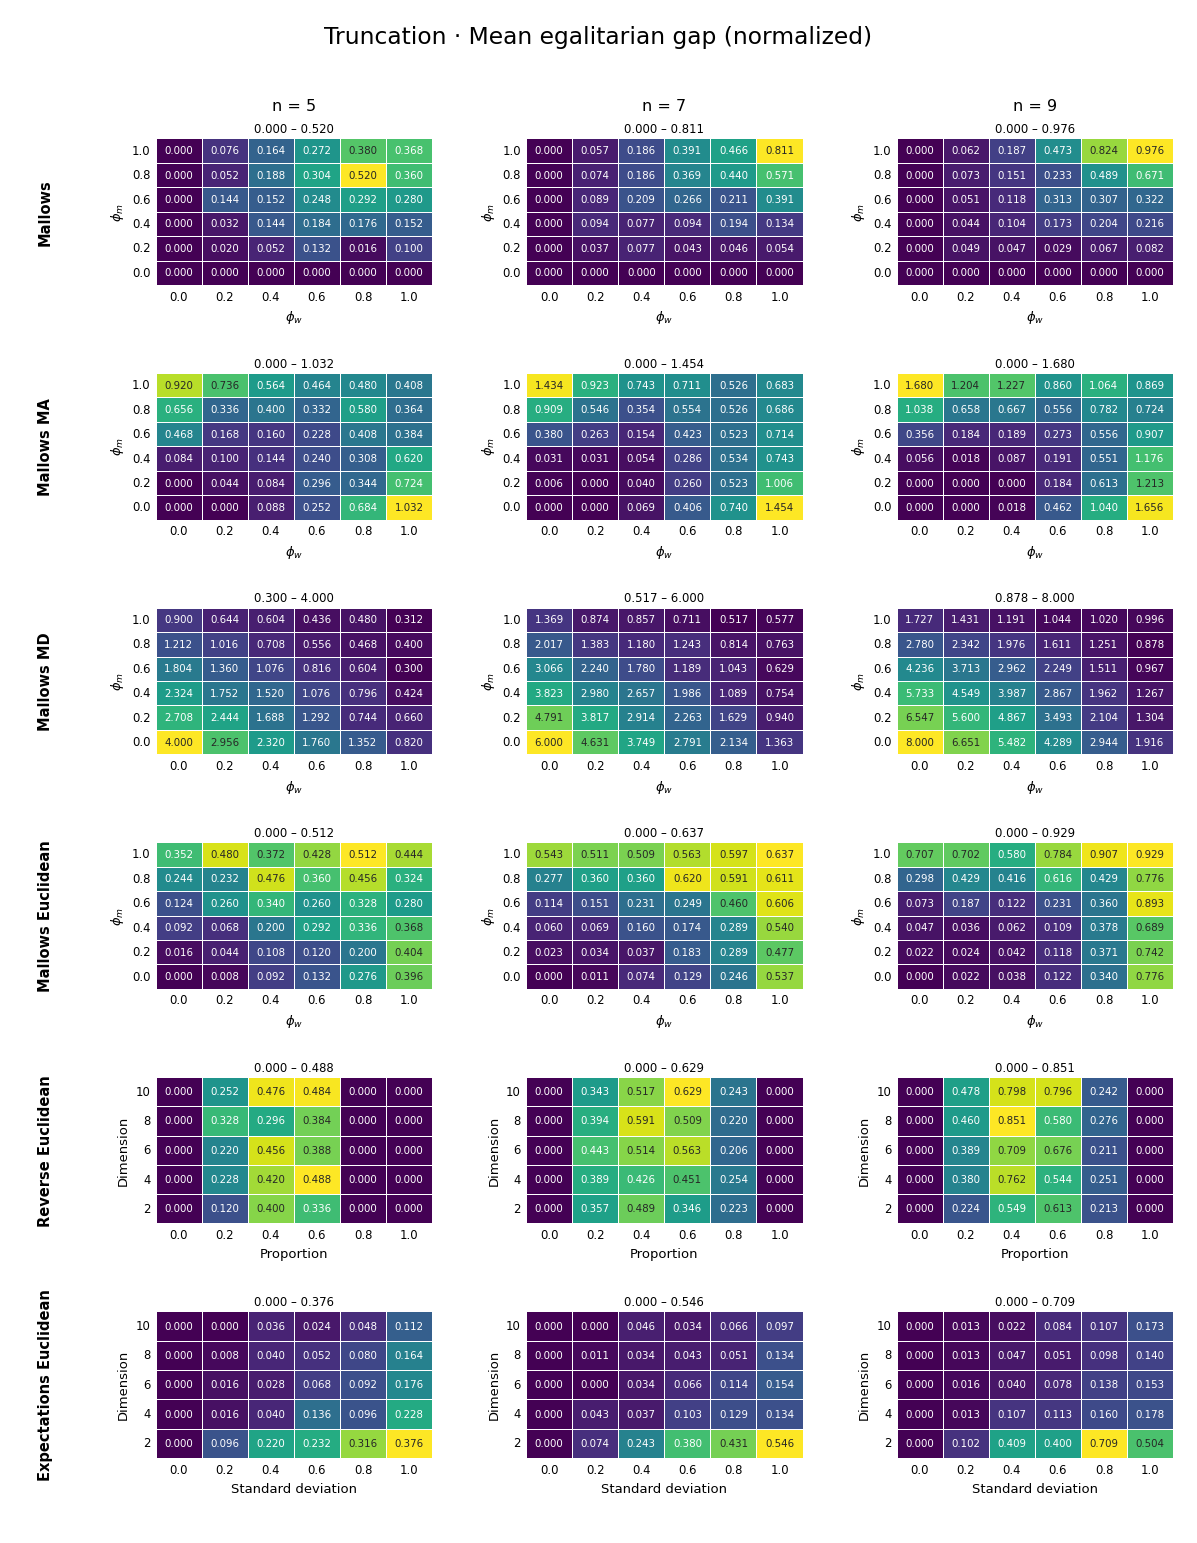

In [6]:
plot_heatmaps("trunc_count", "Truncation · Mean number of beneficiaries", "viridis")
plot_heatmaps("trunc_prevalence", "Truncation · Prevalence", "viridis", prevalence=True)
plot_heatmaps("trunc_egal", "Truncation · Mean egalitarian gap", "viridis")

## Stable lattice size

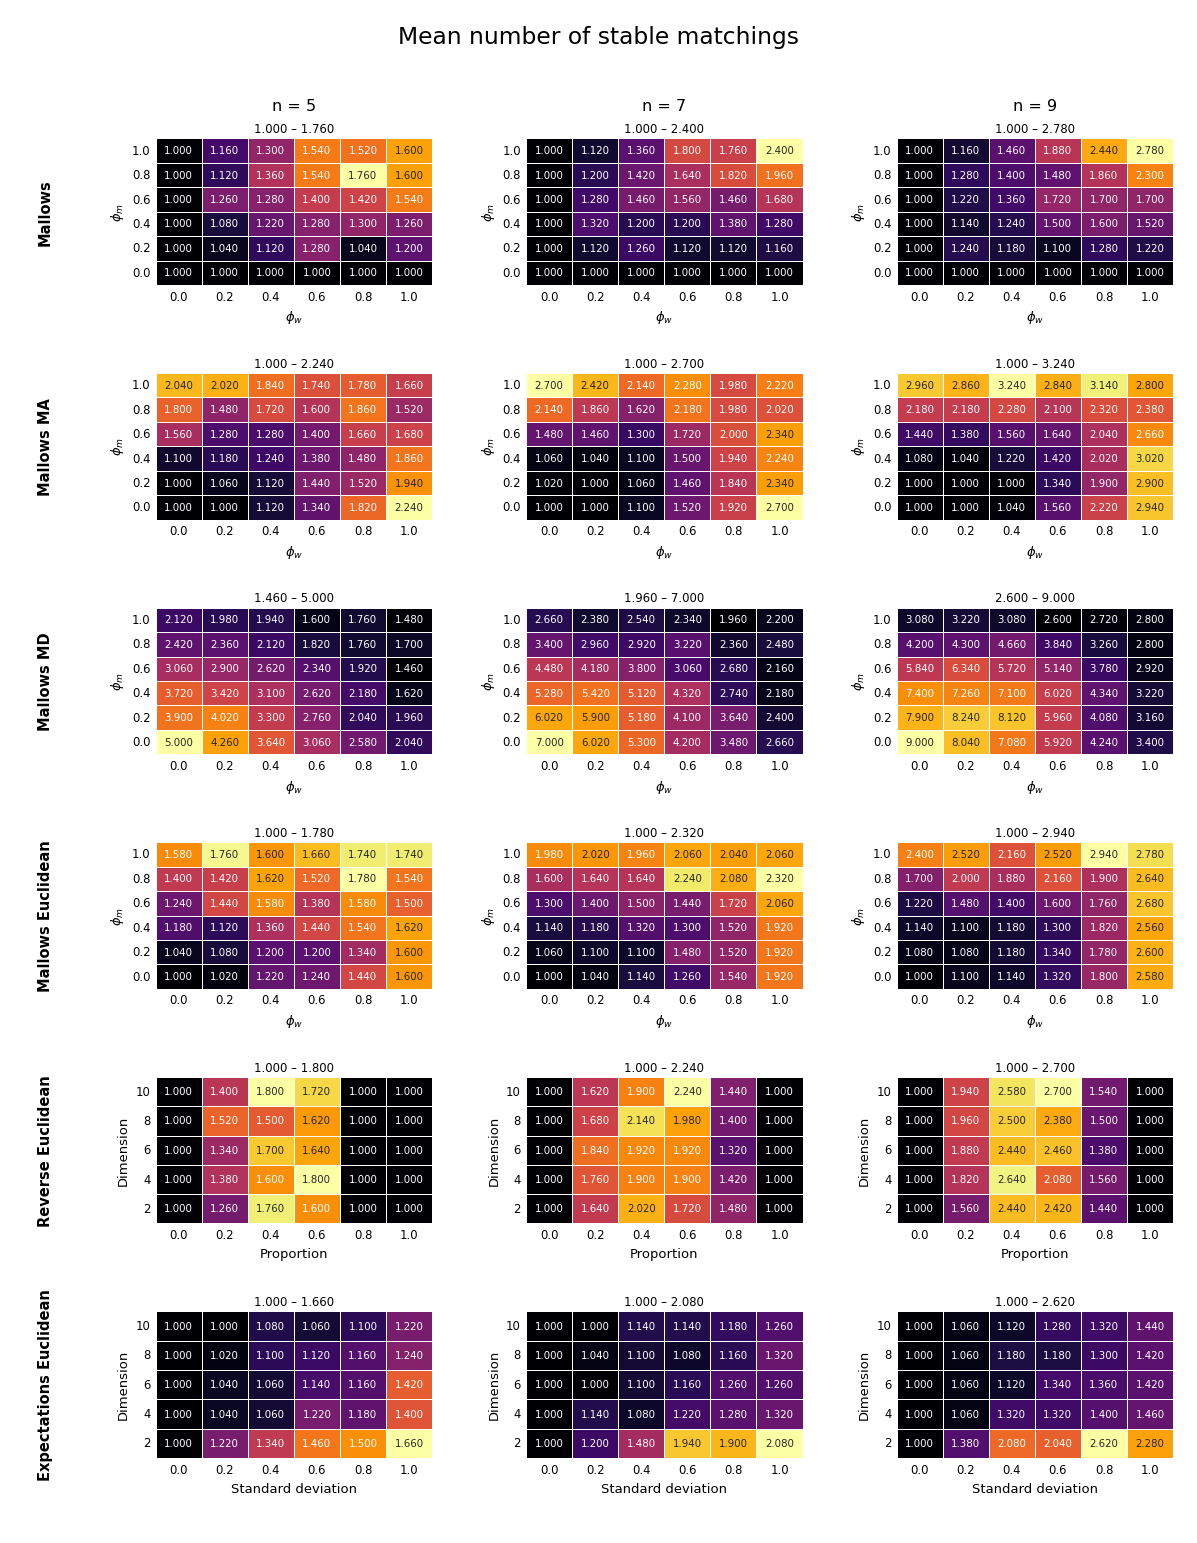

In [7]:
plot_heatmaps("stability_count", "Mean number of stable matchings", "inferno")